# Evidencia 2. Análisis de Aprendizaje Automático · DanuStore

**Equipo 6 · Nexxus Consulting**



**Problemática:** DanuStore acumula inventario de más (sobrestock) en sus combinaciones de producto y región. El equipo lo analiza desde dos enfoques que se presentan **juntos, uno después del otro**, sin mezclar los análisis:

| Parte | Pregunta | Datos | Modelos | Mejor resultado |
|---|---|---|---|---|
| **A. Clustering** | ¿Qué grupos de producto-región existen según su cobertura, precio y stock? | 910 producto-región (promedio de los 24 meses) | K-means vs Jerárquico (3 ajustes cada uno) | K-means C, k = 3 (silueta ≈ 0.352) |
| **B. Clasificación** | ¿Qué nivel de sobrestock (Bajo, Medio, Alto, Crítico) tendrá cada producto-región en los próximos 3 meses? | 19,110 registros producto-región-mes | Árbol de Decisión vs Red Neuronal (3 divisiones) | Red Neuronal, partición 70/30 (F1 macro ≈ 0.818) |

**Cómo ejecutar:** en Google Colab, *Entorno de ejecución → Ejecutar todas*. La sección 0 instala y carga las librerías de las dos partes, monta Google Drive y localiza los archivos de datos. Después, cada parte corre completa y en orden. Las variables de la Parte B (`df`, `X`, `Z`, `datos`, `metricas`, `resultados`, `mejor`, `acciones`, …) **reutilizan nombres** de la Parte A, así que el notebook debe correrse **de arriba hacia abajo**; si se quiere repetir una celda de la Parte A después de correr la Parte B, primero hay que volver a correr la Parte A desde su inicio.

**Archivos de datos** (carpeta del equipo en Drive):
- `data_DanuStore_Equipo6_Mensual.csv` — 21,840 registros (7 regiones × 130 productos × 24 meses, 2024–2025). Lo usan las dos partes.
- `data_DanuStore_Equipo6.csv` — base diaria (≈ 750 MB). Solo la usa el anexo B.11, que lee las primeras 100,000 transacciones; si el archivo no está, el anexo se omite y el resto del notebook corre igual.

**Contenido**

- **Ajustes realizados en la versión final**
- **0.** Configuración común (librerías, Google Drive y datos)
- **Parte A · Clustering (Aldahir):** A.2 Carga y preparación · A.3 Selección de variables · A.4 Estandarización · A.5 Hiperparámetros · A.6 K-means · A.7 Jerárquico · A.8 Comparación de los 6 ajustes · A.9 Comprobación de hiperparámetros · A.10 Interpretación de los clusters · A.11 Biplot · A.12 Aplicación al Objetivo 1 · A.13 Conclusiones
- **Parte B · Clasificación (Javier):** B.2 Importación de datos · B.3 Exploración y selección de variables · B.4 Preprocesamiento · B.5 Hiperparámetros · B.6 Modelado · B.7 Evaluación · B.8 Predicción (demanda esperada × nivel pronosticado) · B.9 Mejor modelo · B.10 Demo · B.11 Anexo diario · B.12 Conclusiones
- **Conclusiones generales del equipo** y **Referencias**

# Ajustes realizados en la versión final

Al integrar los avances individuales en un solo notebook se hicieron estos ajustes:

1. **Un solo notebook para las dos partes:** la carga de librerías, Google Drive y datos se hace una sola vez (sección 0), y cada parte trabaja sobre su propia copia de la base mensual.
2. **Validación temporal como resultado principal del pronóstico:** se aclara que las divisiones 80/20, 70/30 y 60/40 son al azar y que la prueba con meses futuros (B.7.6) es la más confiable.
3. **Nombres de los clusters:** se aclara que el cluster 0 es el que mejor rota de los tres, pero que su cobertura sigue en el rango de baja rotación.
4. **Uso del modelo:** se aclara que las tablas de pronóstico por región (B.10.2) son una demostración y que el desempeño se mide en B.7.
5. **Anexo diario:** solo se reportan resultados que aparecen en las salidas del notebook.
6. **Limitantes y referencias:** se agregaron las limitantes de cada parte y del equipo, y las referencias de los métodos utilizados.


# 0. Configuración común

Esta celda reúne lo que antes estaba repetido al inicio de cada notebook:

- Instala `adjustText` (no viene en Colab; la Parte A la usa en el biplot para que las etiquetas no se encimen).
- Importa **todas** las librerías de las dos partes.
- Monta Google Drive y busca la carpeta de datos. Cada integrante tenía la carpeta con un nombre distinto (`DanuStore Equipo 6` y `Danu Store Equipo 6`), así que se prueban las dos. Fuera de Colab, se buscan los CSV junto al notebook.
- Carga una sola vez la base mensual en `data_DanuStore_Mensual`; cada parte trabaja sobre su propia copia.
- El formato de 3 decimales de las tablas de la Parte A se fija al inicio de la Parte A (A.2) y se restablece al inicio de la Parte B (B.2).
- Define las constantes de la Parte B (`RANDOM_STATE`, `NIVELES`, `COLORES`). La Parte A usa `random_state=123` directamente en sus celdas, igual que en su avance.

In [ ]:
!pip install adjustText -q

import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from adjustText import adjust_text

from scipy.stats import chi2_contingency
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.base import clone
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score
from sklearn.metrics import adjusted_rand_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

# Constantes de la Parte B
RANDOM_STATE = 42
NIVELES = ["Bajo", "Medio", "Alto", "Crítico"]               # niveles para las clases
COLORES = ["#4C9F70", "#F2C14E", "#F78154", "#D1495B"]

# Google Drive (solo en Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print("Fuera de Colab: se buscan los archivos junto al notebook.")

ARCHIVO_MENSUAL = 'data_DanuStore_Equipo6_Mensual.csv'
ARCHIVO_DIARIO = 'data_DanuStore_Equipo6.csv'
CARPETAS = ['/content/drive/MyDrive/DanuStore Equipo 6/',    # carpeta usada en la Parte B
            '/content/drive/MyDrive/Danu Store Equipo 6/',   # carpeta usada en la Parte A
            './']
CARPETA = next((c for c in CARPETAS if os.path.exists(os.path.join(c, ARCHIVO_MENSUAL))), None)
if CARPETA is None:
    raise FileNotFoundError(f"No se encontró {ARCHIVO_MENSUAL} en: {CARPETAS}. Actualiza la lista CARPETAS.")

data_DanuStore_Mensual = pd.read_csv(os.path.join(CARPETA, ARCHIVO_MENSUAL))
RUTA_DIARIO = os.path.join(CARPETA, ARCHIVO_DIARIO)
print("Carpeta de datos:", CARPETA)
print("Base mensual:", data_DanuStore_Mensual.shape, "| Base diaria disponible:", os.path.exists(RUTA_DIARIO))

Fuera de Colab: se buscan los archivos junto al notebook.
Carpeta de datos: ./
Base mensual: (21840, 20) | Base diaria disponible: False


# PARTE A · Modelos de Clustering

**Objetivo:** agrupar las 910 combinaciones producto-región según su inventario (cobertura, precio y stock) para proponer una estrategia distinta por grupo. Se comparan **K-means** y **Agrupamiento jerárquico**, cada uno con 3 ajustes.

## A.1 Librerías

Las librerías de esta parte (`pandas`, `numpy`, `matplotlib`, `seaborn`, `adjustText`, `StandardScaler`, `PCA`, `KMeans`, las métricas de clustering y `linkage`/`dendrogram`/`fcluster` de `scipy`) y la conexión con Google Drive ya se cargaron en la **sección 0**.

## A.2 Carga y preparación de los datos

Cargué el archivo mensual (21,840 registros producto-región-mes). Como las decisiones de inventario se toman por producto en cada región, resumí los 24 meses de cada producto-región en **un solo registro**, calculando el promedio de sus ventas, inventario, cumplimiento y cobertura.

In [ ]:
# CARGA DE DATOS

pd.options.display.float_format = '{:.3f}'.format   # formato de 3 decimales de la Parte A
df_mensual = data_DanuStore_Mensual.copy()   # cargada en la sección 0
print(df_mensual.shape)
df_mensual.head()

(21840, 20)


,month,year,product_id,region,units_expected,stock,percentage,units_sold,sales_amount,product_name,category,subcategory,static_price,inventory_key,Ventas_Acumuladas_Mensual,Stock_Restante_Mensual,Cumplimiento_Venta_Esperada,Product_Repeat_Purchase_Rate,Venta_Promedio_Diaria,Dias_Cobertura_Inventario
0,March,2025,39,Bajío,1057,1735,164.140,107,4045.320,Shirts Product 39,Casual Wear,Shirts,45.400,Bajío_39_March_2025,107,1628,10.120,99.920,3.452,502.660
1,October,2025,46,Ciudad de México,1983,3215,162.130,671,49978.140,Pants Product 46,Casual Wear,Pants,87.100,Ciudad de México_46_October_2025,671,2544,33.840,99.890,21.645,148.530
2,May,2025,113,Ciudad de México,2549,4030,158.100,693,52325.530,Boots Product 113,Footwear,Boots,88.060,Ciudad de México_113_May_2025,693,3337,27.190,99.880,22.355,180.270
3,February,2025,75,Ciudad de México,1388,2192,157.930,355,23911.750,Jewelry Product 75,Accessories,Jewelry,79.430,Ciudad de México_75_February_2025,355,1837,25.580,99.840,12.679,172.890
4,October,2025,84,Ciudad de México,1458,2298,157.610,467,18204.740,Hats Product 84,Accessories,Hats,44.880,Ciudad de México_84_October_2025,467,1831,32.030,99.780,15.065,152.540


Ahora se deja un renglón por cada producto × región (130 productos × 7 regiones = 910 registros)

In [ ]:
# UN REGISTRO POR PRODUCTO-REGIÓN

df = df_mensual.groupby(['product_id', 'region', 'product_name', 'category', 'subcategory']).agg(
    venta_prom=('units_sold', 'mean'),                      # unidades vendidas al mes
    venta_std=('units_sold', 'std'),                        # variación de las ventas
    esperado_prom=('units_expected', 'mean'),               # unidades que esperaba vender la empresa
    stock_prom=('stock', 'mean'),                           # inventario promedio
    cumplimiento_prom=('Cumplimiento_Venta_Esperada', 'mean'),  # % de lo esperado que se vendió
    cobertura_prom=('Dias_Cobertura_Inventario', 'mean'),   # días que tarda en venderse el inventario
    precio=('static_price', 'first'),                       # precio del producto
    monto_prom=('sales_amount', 'mean'),                    # dinero vendido al mes
    recompra_prom=('Product_Repeat_Purchase_Rate', 'mean')  # tasa de recompra
).reset_index()

df['cv_ventas'] = df['venta_std'] / df['venta_prom'] # coeficiente de variación: qué tan estables son las ventas
df = df.drop(columns='venta_std')

print(df.shape)
df.head()

(910, 14)


,product_id,region,product_name,category,subcategory,venta_prom,esperado_prom,stock_prom,cumplimiento_prom,cobertura_prom,precio,monto_prom,recompra_prom,cv_ventas
0,1,Bajío,Tops Product 1,Fitness Wear,Tops,158.500,1357.125,1625.500,11.752,320.943,35.160,4716.318,99.910,0.183
1,1,Ciudad de México,Tops Product 1,Fitness Wear,Tops,587.958,1678.958,1927.500,34.948,102.520,35.160,17512.700,99.910,0.223
2,1,Noroeste,Tops Product 1,Fitness Wear,Tops,110.250,1232.958,1283.042,9.014,367.346,35.160,3273.201,99.910,0.230
3,1,Sur,Tops Product 1,Fitness Wear,Tops,93.792,1070.917,1091.333,8.899,360.091,35.160,2783.399,99.910,0.188
4,1,Sureste,Tops Product 1,Fitness Wear,Tops,86.625,1167.250,1155.417,7.441,428.433,35.160,2584.930,99.910,0.214


In [ ]:
# TIPOS DE DATOS

categoricas = ['product_id', 'region', 'product_name', 'category', 'subcategory']
numericas = ['venta_prom', 'esperado_prom', 'stock_prom', 'cumplimiento_prom', 'cobertura_prom',
             'cv_ventas', 'precio', 'monto_prom', 'recompra_prom']

df[categoricas] = df[categoricas].astype('category') #categóricas
df[numericas] = df[numericas].apply(pd.to_numeric, errors='coerce') #numéricas
print('Valores nulos:', df.isna().sum().sum())
df[numericas].describe().T

Valores nulos: 0


,count,mean,std,min,25%,50%,75%,max
venta_prom,910.000,207.547,169.433,29.250,83.906,138.604,290.021,840.083
esperado_prom,910.000,1222.494,407.249,467.292,905.573,1212.979,1498.375,2406.500
stock_prom,910.000,1358.549,509.076,450.292,975.823,1303.750,1696.177,2938.375
cumplimiento_prom,910.000,15.694,9.222,4.957,8.567,11.901,20.439,37.285
cobertura_prom,910.000,289.352,130.816,95.000,171.081,293.564,379.253,667.435
cv_ventas,910.000,0.203,0.053,0.088,0.165,0.197,0.235,0.488
precio,910.000,83.644,44.379,21.990,48.670,77.185,104.500,231.680
monto_prom,910.000,14506.751,15176.174,788.846,4787.509,8919.958,18252.420,115904.935
recompra_prom,910.000,99.845,0.219,98.030,99.870,99.900,99.920,100.000


Obtuve **910 registros** (130 productos × 7 regiones) sin valores nulos. La cobertura va desde menos de 100 hasta más de 600 días, y la tasa de recompra casi no varía (alrededor de 99.8).

## A.3 Selección de variables

### A.3.1 Correlaciones

Utilicé la correlación de **Spearman**, ya que fue la que mejor funcionó en la etapa 4.3 (los datos tienen valores extremos y no todas las relaciones son lineales).

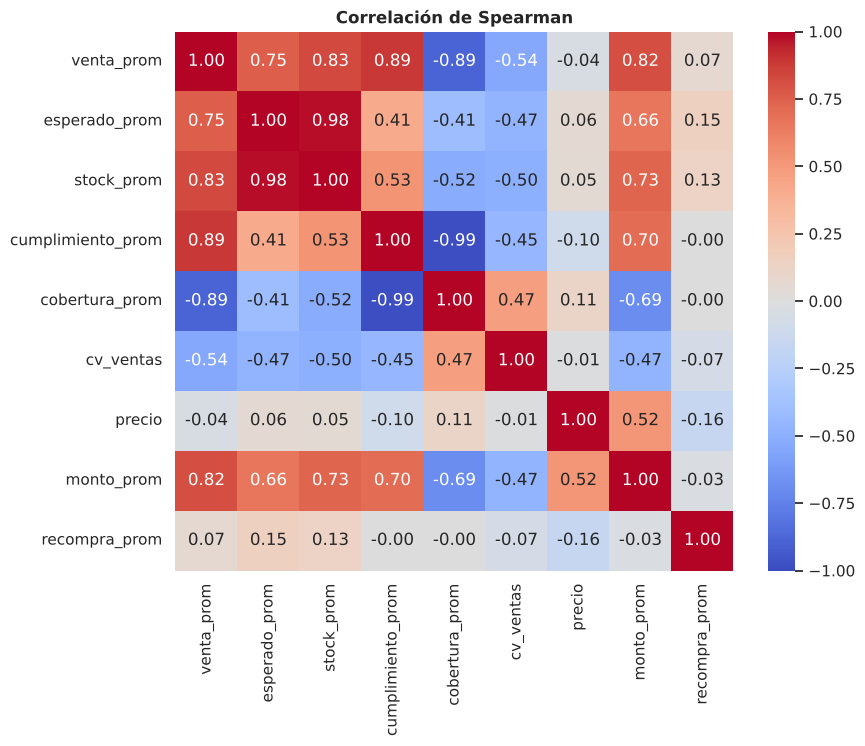

In [ ]:
corr = df[numericas].corr(method='spearman').round(2)

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Correlación de Spearman', fontweight='bold')
plt.show()

- `cumplimiento_prom` y `cobertura_prom` están casi 100% relacionadas de forma negativa (≈ -0.99): mientras más se vende, mayor es el cumplimiento y menor la cobertura.
- `esperado_prom` y `stock_prom` también están casi 100% relacionadas (≈ 0.98), ya que el inventario se asigna con base en el pronóstico.
- `venta_prom` está muy relacionada con el cumplimiento y la cobertura (≈ 0.89), y `monto_prom` es la venta multiplicada por el precio.
- `recompra_prom` no se relaciona con ninguna variable, y el precio casi no se relaciona con las demás.

### A.3.2 Análisis de PCA

Apliqué un PCA a las variables estandarizadas para confirmar si existe una relación alta entre variables. Si pocos componentes explican casi toda la información, significa que varias variables dicen lo mismo.

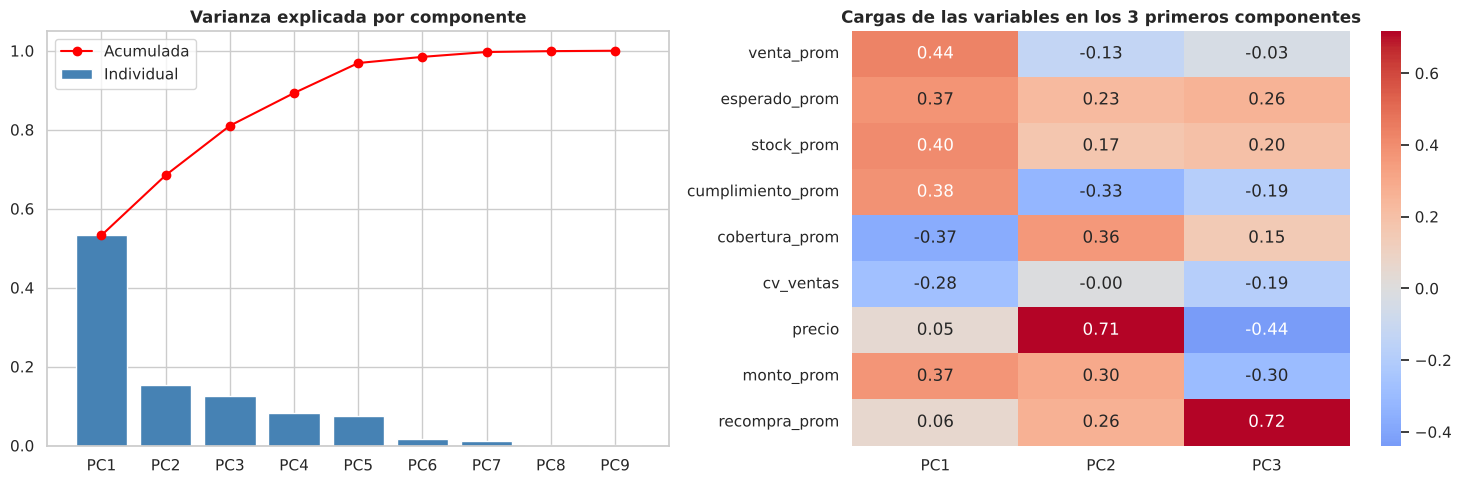

,Varianza explicada,Varianza acumulada
PC1,0.532,0.532
PC2,0.152,0.685
PC3,0.125,0.810
PC4,0.083,0.893
PC5,0.076,0.969
PC6,0.016,0.984
PC7,0.012,0.997
PC8,0.002,0.999
PC9,0.001,1.000


In [ ]:
X_universo = StandardScaler().fit_transform(df[numericas])
pca_universo = PCA().fit(X_universo)

varianza = pd.DataFrame({'Varianza explicada': pca_universo.explained_variance_ratio_,
                         'Varianza acumulada': pca_universo.explained_variance_ratio_.cumsum()},
                        index=[f'PC{i + 1}' for i in range(len(numericas))])

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].bar(varianza.index, varianza['Varianza explicada'], color='steelblue', label='Individual')
ax[0].plot(varianza.index, varianza['Varianza acumulada'], color='red', marker='o', label='Acumulada')
ax[0].set_title('Varianza explicada por componente', fontweight='bold')
ax[0].legend()

cargas = pd.DataFrame(pca_universo.components_[:3].T, index=numericas, columns=['PC1', 'PC2', 'PC3'])
sns.heatmap(cargas, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[1])
ax[1].set_title('Cargas de las variables en los 3 primeros componentes', fontweight='bold')
plt.tight_layout()
plt.show()

varianza

Con **3 componentes se explica ≈ 81% de la información** de las 9 variables. El **PC1** agrupa ventas, cumplimiento, cobertura, stock y pronóstico, es decir **que tan rápido se vende el inventario**; el **PC2** representa el **precio** (carga de ≈ 0.71) y el PC3 la recompra.

### A.3.3 Variables seleccionadas

El PCA mostró que la información se concentra en dos ideas: **que tan rápido se vende el inventario** (PC1) y el **precio** (PC2). Además, para el Objetivo 1 me interesa que el **tamaño del inventario** también forme parte del modelo. Por eso decidí utilizar **3 variables**, una por cada idea:

| Variable | Decisión | Justificación |
|---|---|---|
| `cobertura_prom` | Se conserva (con logaritmo) | Indica qué tan lento se vende el inventario; es el indicador directo del sobreinventario y representa al PC1 |
| `precio` | Se conserva | Indica cuánto vale cada pieza; representa al PC2 |
| `stock_prom` | Se conserva (con logaritmo) | Indica qué tan grande es el inventario de cada producto-región |
| `venta_prom`, `cumplimiento_prom` | Se eliminan | Están muy relacionadas con la cobertura (≈ 0.89 y ≈ -0.99), por lo que repiten la misma información |
| `esperado_prom` | Se elimina | Está casi 100% relacionada con el stock (≈ 0.98), ya que el inventario se asigna con base en el pronóstico |
| `cv_ventas` | Se elimina | Su relación con la cobertura es moderada y casi no aporta a la separación de los grupos |
| `monto_prom` | Se elimina | Es venta × precio |
| `recompra_prom` | Se elimina | Casi no varía |

Las tres variables seleccionadas dicen cosas distintas: la cobertura y el stock tienen una relación moderada (≈ -0.52) y el precio casi no se relaciona con ninguna por lo que ninguna idea se cuenta dos veces. Las variables eliminadas no se pierden: las utilicé después para **interpretar** los grupos.

## A.4 Estandarización

- A la cobertura y al stock les apliqué **logaritmo**, ya que tienen valores muy extremos y K-means es sensible a ellos.
- La **estandarización es necesaria**, porque ambos modelos agrupan por distancia. Sin ella, el stock (que va de 450 a más de 2,000) pesaría mucho más que el precio o la cobertura.
- No fue necesario codificar variables categóricas, ya que solo las utilicé para interpretar los grupos.

In [ ]:
# ESTANDARIZACIÓN

df['log_cobertura'] = np.log(df['cobertura_prom'])
df['log_stock'] = np.log(df['stock_prom'])
variables = ['log_cobertura', 'precio', 'log_stock']

scaler = StandardScaler()
X = scaler.fit_transform(df[variables]) # X = variables estandarizadas que utilicé en los modelos

## A.5 Hiperparámetros utilizados

Para cada modelo utilicé **3 hiperparámetros**, y con ellos armé **3 ajustes** distintos.

### A.5.1 Modelo 1: K-means

| Hiperparámetro | Qué controla | Valores utilizados |
|---|---|---|
| `n_clusters` | Número de grupos | 2 a 10 (para elegir el óptimo) |
| `init` | Cómo se eligen los centros iniciales | `'k-means++'` (centros separados entre sí) o `'random'` (al azar) |
| `n_init` | Cuántas veces se repite el algoritmo con distintos inicios (se queda con el mejor) | 10, 20 o 50 |

| Ajuste | `init` | `n_init` |
|---|---|---|
| K-means A | `'k-means++'` | 10 |
| K-means B | `'random'` | 20 |
| K-means C | `'k-means++'` | 50 |

En los tres ajustes utilicé `random_state=123`, para que el resultado se pueda repetir.

### A.5.2 Modelo 2: Agrupamiento jerárquico

| Hiperparámetro | Qué controla | Valores utilizados |
|---|---|---|
| `t` (en `fcluster`) | Número de grupos en que se corta el dendrograma | 2 a 10 (para elegir el óptimo) |
| `method` | Cómo se mide la distancia entre dos grupos al unirlos | `'ward'`, `'average'` o `'complete'` |
| `metric` | Cómo se mide la distancia entre dos puntos | `'euclidean'`, `'cityblock'` (Manhattan) o `'cosine'` |

| Ajuste | `method` | `metric` |
|---|---|---|
| Jerárquico A | `'ward'` | `'euclidean'` |
| Jerárquico B | `'average'` | `'cityblock'` |
| Jerárquico C | `'complete'` | `'cosine'` |

**Hiperparámetros en común:** los dos modelos utilizan el **mismo número de grupos** (de 2 a 10) y las **mismas variables estandarizadas**. Además, K-means y el Jerárquico A (`ward` + `euclidean`) buscan lo mismo: formar grupos con la menor variación posible dentro de cada uno, por lo que son la comparación más justa entre ambos modelos.

In [ ]:
ajustes_kmeans = {
    'K-means A': {'init': 'k-means++', 'n_init': 10},
    'K-means B': {'init': 'random', 'n_init': 20},
    'K-means C': {'init': 'k-means++', 'n_init': 50}
}

ajustes_jerarquico = {
    'Jerárquico A': {'method': 'ward', 'metric': 'euclidean'},
    'Jerárquico B': {'method': 'average', 'metric': 'cityblock'},
    'Jerárquico C': {'method': 'complete', 'metric': 'cosine'}
}

valores_k = range(2, 11)

## A.6 Modelo 1: K-means

K-means elige *k* centros, asigna cada producto-región al centro más cercano, recalcula los centros como el promedio de su grupo y repite hasta que los grupos ya no cambian.

Para elegir el número de clusters utilicé el **método del codo** (WCSS) y la **silueta**, probando k = 2 a 10 con los 3 ajustes.

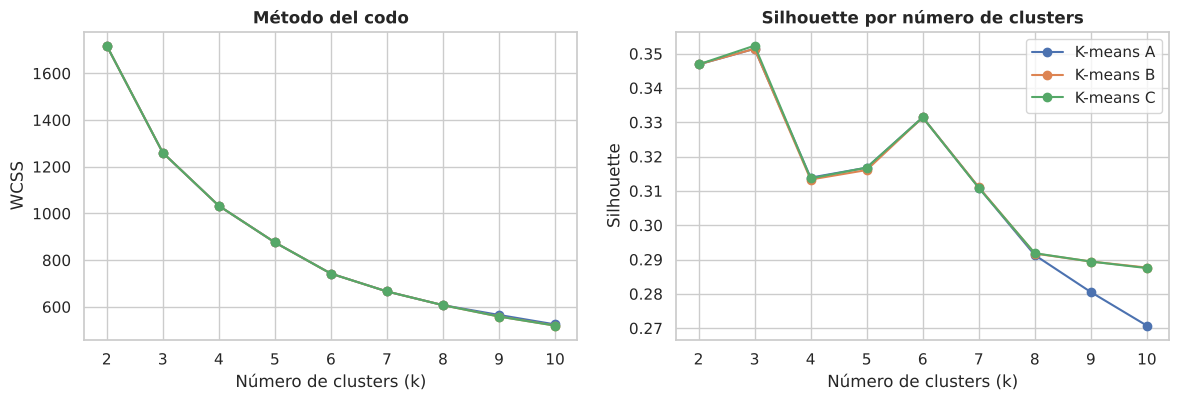

In [ ]:
resultados = []

for nombre, params in ajustes_kmeans.items():
    for k in valores_k:
        kmeans = KMeans(n_clusters=k, init=params['init'], n_init=params['n_init'], random_state=123)
        etiquetas = kmeans.fit_predict(X)
        resultados.append({'Modelo': 'K-means', 'Ajuste': nombre, 'k': k,
                           'WCSS': kmeans.inertia_,
                           'Silhouette': silhouette_score(X, etiquetas),
                           'Calinski-Harabasz': calinski_harabasz_score(X, etiquetas),
                           'Davies-Bouldin': davies_bouldin_score(X, etiquetas),
                           'Cluster más pequeño': np.bincount(etiquetas).min()})
resultados_kmeans = pd.DataFrame(resultados)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for nombre in ajustes_kmeans:
    datos = resultados_kmeans[resultados_kmeans['Ajuste'] == nombre]
    ax[0].plot(datos['k'], datos['WCSS'], marker='o', label=nombre)
    ax[1].plot(datos['k'], datos['Silhouette'], marker='o', label=nombre)
ax[0].set_title('Método del codo', fontweight='bold')
ax[0].set_xlabel('Número de clusters (k)')
ax[0].set_ylabel('WCSS')
ax[1].set_title('Silhouette por número de clusters', fontweight='bold')
ax[1].set_xlabel('Número de clusters (k)')
ax[1].set_ylabel('Silhouette')
ax[1].legend()
plt.show()

- El **codo** no es tan marcado, pero la WCSS baja mucho de k = 2 a k = 3 (de aprox. 1,720 a 1,260) y a partir de ahí baja más despacio.
- La **silueta más alta se obtiene con k = 3** (≈ 0.35), por lo que el codo y la silueta coinciden. Además, 3 grupos son justo los que se necesitan para el Objetivo 1 (buena rotación, rotación media y sobrestock), por lo que trabajé con **k = 3**.
- Los 3 ajustes dan prácticamente las mismas curvas; solo cambian un poco con muchos grupos (k = 9 y 10).

## A.7 Modelo 2: Agrupamiento jerárquico

El agrupamiento jerárquico inicia con cada producto-región como un grupo individual y va uniendo los dos grupos más parecidos hasta formar un solo grupo. El resultado se observa en el **dendrograma**, que se "corta" en el número de grupos deseado.

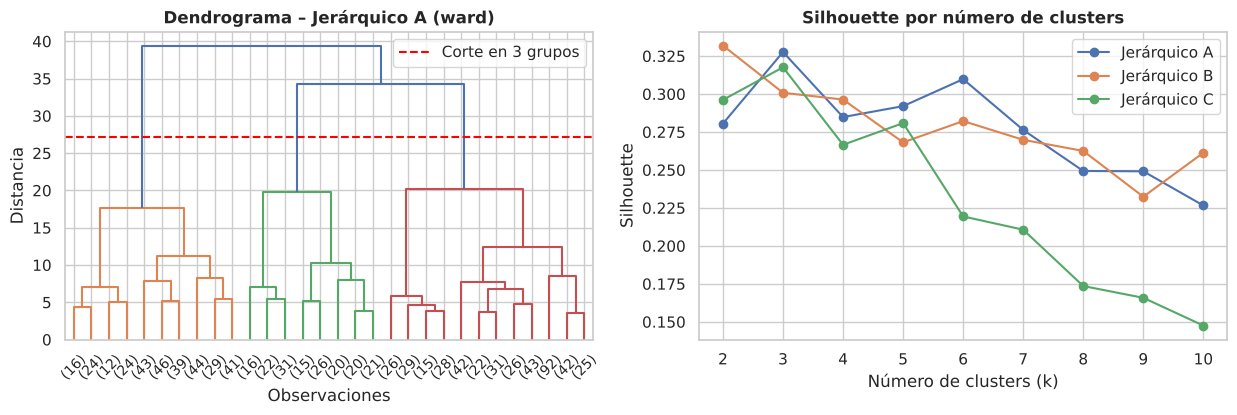

In [ ]:
resultados = resultados_kmeans.to_dict('records')   # parte de los resultados de K-means (permite re-ejecutar la celda)
for nombre, params in ajustes_jerarquico.items():
    Z = linkage(X, method=params['method'], metric=params['metric']) # Z es la matriz de enlace
    for k in valores_k:
        etiquetas = fcluster(Z, t=k, criterion='maxclust') # cortar el dendrograma en k grupos
        resultados.append({'Modelo': 'Jerárquico', 'Ajuste': nombre, 'k': k,
                           'WCSS': np.nan,
                           'Silhouette': silhouette_score(X, etiquetas),
                           'Calinski-Harabasz': calinski_harabasz_score(X, etiquetas),
                           'Davies-Bouldin': davies_bouldin_score(X, etiquetas),
                           'Cluster más pequeño': np.bincount(etiquetas)[1:].min()})
resultados = pd.DataFrame(resultados)

# Dendrograma del ajuste A (ward) con el corte en 3 grupos
Z = linkage(X, method='ward', metric='euclidean')
corte = (Z[-3, 2] + Z[-2, 2]) / 2 # altura en la que el dendrograma queda dividido en 3 grupos
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
dendrogram(Z, truncate_mode='lastp', p=30, color_threshold=corte, ax=ax[0]) # últimas 30 uniones para que se pueda leer
ax[0].axhline(y=corte, color='red', linestyle='--', label='Corte en 3 grupos')
ax[0].set_title('Dendrograma – Jerárquico A (ward)', fontweight='bold')
ax[0].set_xlabel('Observaciones')
ax[0].set_ylabel('Distancia')
ax[0].legend()

for nombre in ajustes_jerarquico:
    datos = resultados[resultados['Ajuste'] == nombre]
    ax[1].plot(datos['k'], datos['Silhouette'], marker='o', label=nombre)
ax[1].set_title('Silhouette por número de clusters', fontweight='bold')
ax[1].set_xlabel('Número de clusters (k)')
ax[1].set_ylabel('Silhouette')
ax[1].legend()
plt.show()

- En el dendrograma, las líneas verticales más largas están en las últimas uniones, y al cortar en la línea roja se forman **3 grupos**, lo que coincide con el codo y la silueta de K-means.
- El ajuste **A (ward)** tiene su silueta más alta justo en k = 3 (≈ 0.33). El ajuste **B (average, cityblock)** tiene su mejor silueta en k = 2, y el **C (complete, cosine)** queda por debajo del A.

## A.8 Comparación de los 6 ajustes con k = 3

Comparé los 6 ajustes con **k = 3** utilizando tres métricas:

- **Silhouette:** qué tan bien está cada punto en su grupo (de -1 a 1, **más alto es mejor**)
- **Calinski-Harabasz:** qué tan separados están los grupos (**más alto es mejor**)
- **Davies-Bouldin:** qué tan parecido es cada grupo a su grupo más cercano (**más bajo es mejor**).

Para elegir el mejor ajuste seguí estas reglas:
1. Se descartan los ajustes con algún grupo de **menos del 5% de los datos** (menos de 46 producto-región), porque un grupo tan pequeño no sirve para tomar decisiones.
2. De los que quedan, gana el de **mayor silueta**.

In [ ]:
k_final = 3
comparacion = resultados[resultados['k'] == k_final].drop(columns='k').reset_index(drop=True)
comparacion['Válido'] = comparacion['Cluster más pequeño'] >= 0.05 * len(X)
comparacion = comparacion.sort_values('Silhouette', ascending=False).reset_index(drop=True)
comparacion

,Modelo,Ajuste,WCSS,Silhouette,Calinski-Harabasz,Davies-Bouldin,Cluster más pequeño,Válido
0,K-means,K-means C,1260.229,0.352,528.905,1.027,169,True
1,K-means,K-means A,1260.265,0.351,528.876,1.032,173,True
2,K-means,K-means B,1260.265,0.351,528.876,1.032,173,True
3,Jerárquico,Jerárquico A,NaN,0.328,449.324,1.097,171,True
4,Jerárquico,Jerárquico C,NaN,0.318,449.078,1.111,165,True
5,Jerárquico,Jerárquico B,NaN,0.301,366.194,1.062,48,True


In [ ]:
validos = comparacion[comparacion['Válido']]
mejor = validos.iloc[0]
kmeans_validos = validos[validos['Modelo'] == 'K-means']

print(f"Mejor modelo: {mejor['Modelo']} | Mejor ajuste: {mejor['Ajuste']} ({ajustes_jerarquico.get(mejor['Ajuste'], ajustes_kmeans.get(mejor['Ajuste']))})")
print(f"  Silhouette = {mejor['Silhouette']:.3f} | Calinski-Harabasz = {mejor['Calinski-Harabasz']:.1f} | Davies-Bouldin = {mejor['Davies-Bouldin']:.3f}")
print('Silueta de los ajustes de K-means:', dict(zip(kmeans_validos['Ajuste'], kmeans_validos['Silhouette'].round(4))))

Mejor modelo: K-means | Mejor ajuste: K-means C ({'init': 'k-means++', 'n_init': 50})
  Silhouette = 0.352 | Calinski-Harabasz = 528.9 | Davies-Bouldin = 1.027
Silueta de los ajustes de K-means: {'K-means C': 0.3523, 'K-means A': 0.3514, 'K-means B': 0.3514}


- Los **3 ajustes de K-means** son los **mejores en las tres métricas** (silueta ≈ 0.35, mayor Calinski-Harabasz y menor Davies-Bouldin), por lo que **K-means es el mejor modelo**.
- Entre los tres ajustes de K-means casi no hay diferencia (la silueta solo cambia en el tercer decimal), pero el **ajuste C (`k-means++`, `n_init=50`)** es el que tiene la silueta más alta (≈ 0.352).
- El **Jerárquico A (ward, euclidean)** es el mejor de los jerárquicos (≈ 0.328), un poco abajo de K-means. Los **Jerárquicos B y C** quedan más abajo; el B casi queda descartado ya que su grupo más pequeño tiene 48 producto-región, justo arriba del límite de 46.

### A.8.1 Comparación visual de las métricas

Para ver de forma más clara cuál ajuste fue mejor, grafiqué las tres métricas de los 6 ajustes. Primero con **k = 3** (barras) y después cómo cambian con distinto número de grupos (líneas).

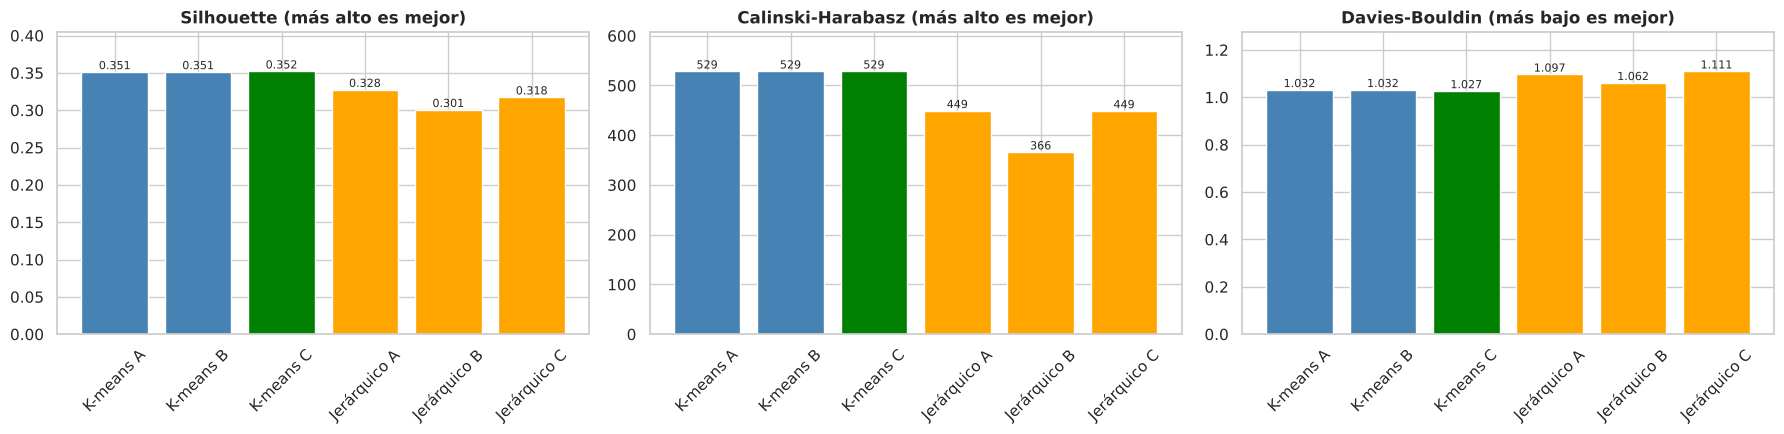

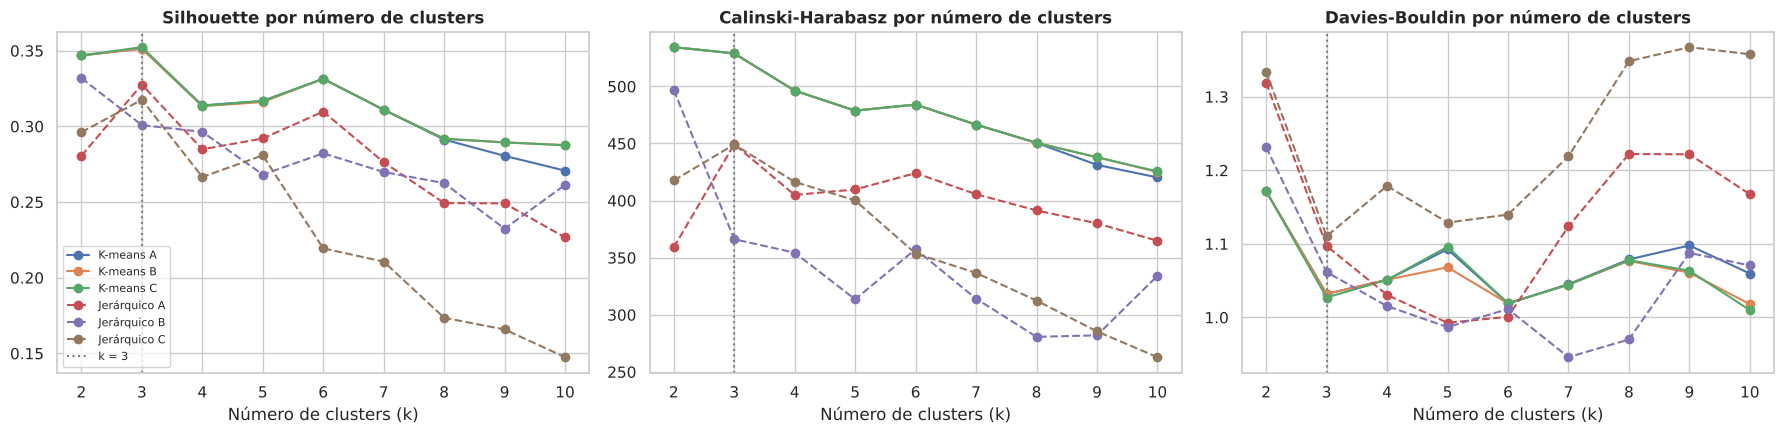

In [ ]:
metricas = {'Silhouette': 'más alto es mejor', 'Calinski-Harabasz': 'más alto es mejor', 'Davies-Bouldin': 'más bajo es mejor'}
orden_ajustes = list(ajustes_kmeans) + list(ajustes_jerarquico)
datos_k3 = comparacion.set_index('Ajuste').loc[orden_ajustes]

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for i, (metrica, regla) in enumerate(metricas.items()):
    valores = datos_k3[metrica]
    mejor_valor = valores.min() if metrica == 'Davies-Bouldin' else valores.max()
    # verde = el mejor ajuste, azul = K-means, naranja = jerárquico
    colores_barras = ['green' if v == mejor_valor else ('steelblue' if 'K-means' in a else 'orange') for a, v in valores.items()]
    barras = ax[i].bar(valores.index, valores.values, color=colores_barras)
    ax[i].bar_label(barras, fmt='%.3f' if metrica != 'Calinski-Harabasz' else '%.0f', fontsize=8)
    ax[i].set_title(f'{metrica} ({regla})', fontweight='bold')
    ax[i].tick_params(axis='x', rotation=45)
    ax[i].set_ylim(0, valores.max() * 1.15)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for i, metrica in enumerate(metricas):
    for nombre in orden_ajustes:
        datos = resultados[resultados['Ajuste'] == nombre]
        estilo = '-' if 'K-means' in nombre else '--' # línea continua = K-means, punteada = jerárquico
        ax[i].plot(datos['k'], datos[metrica], marker='o', linestyle=estilo, label=nombre)
    ax[i].axvline(k_final, color='gray', linestyle=':', label='k = 3')
    ax[i].set_title(f'{metrica} por número de clusters', fontweight='bold')
    ax[i].set_xlabel('Número de clusters (k)')
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lo que muestran las gráficas:**

- **Barras (k = 3):** en las tres métricas el mejor es el **K-means C** (en verde). Los tres ajustes de K-means (azul) quedan casi iguales y todos por arriba de los jerárquicos (naranja); la diferencia entre ellos es muy pequeña porque los tres llegan casi a la misma solución.
- **Líneas por número de grupos:** las líneas continuas de K-means quedan por arriba de los jerárquicos en la silueta y en Calinski-Harabasz para casi cualquier número de grupos, o sea que K-means fue mejor sin importar el k. También se ve que en **k = 3** está el punto más alto de la silueta de K-means y del Jerárquico A. En Davies-Bouldin con más grupos algunos jerárquicos bajan un poco, pero en k = 3 K-means sigue siendo el mejor.

Esto confirma de forma visual lo que se vio en la tabla: el mejor modelo es **K-means** y el mejor ajuste es el **C**.

## A.9 Comprobación de los mejores hiperparámetros

### A.9.1 ¿Cuál ajuste de K-means es más estable?

Como los 3 ajustes de K-means quedaron casi empatados, revisé si dan **el mismo resultado** si se cambia la semilla (`random_state` de 0 a 9), comparando contra el resultado del ajuste C. Para comparar dos agrupaciones utilicé el **Adjusted Rand Index (ARI)**: 1 significa que son idénticas.

In [ ]:
referencia = KMeans(n_clusters=k_final, init='k-means++', n_init=50, random_state=123).fit_predict(X) # resultado del ajuste C
estabilidad = []
for nombre, params in ajustes_kmeans.items():
    ari = [adjusted_rand_score(referencia, KMeans(n_clusters=k_final, init=params['init'], n_init=params['n_init'],
                                                  random_state=semilla).fit_predict(X)) for semilla in range(10)]
    estabilidad.append({'Ajuste': nombre, **params, 'ARI promedio': np.mean(ari),
                        'ARI mínimo': np.min(ari),
                        'Veces con casi el mismo resultado (ARI > 0.95, de 10)': sum(np.array(ari) > 0.95)})
pd.DataFrame(estabilidad)

,Ajuste,init,n_init,ARI promedio,ARI mínimo,"Veces con casi el mismo resultado (ARI > 0.95, de 10)"
0,K-means A,k-means++,10,0.994,0.985,10
1,K-means B,random,20,0.999,0.994,10
2,K-means C,k-means++,50,1.000,1.000,10


Los tres ajustes son **muy estables** (ARI arriba de 0.98 con todas las semillas), o sea, sin importar la semilla forman prácticamente los mismos grupos y solo cambian unos cuantos producto-región de la frontera. El **ajuste C** es el único que da **exactamente el mismo resultado con las 10 semillas** (ARI = 1), y además es el de mayor silueta, por lo que seleccioné el **ajuste C (`init='k-means++'`, `n_init=50`)**.

### A.9.2 ¿K-means y el jerárquico encuentran los mismos grupos?

In [ ]:
kmeans_final = KMeans(n_clusters=k_final, init='k-means++', n_init=50, random_state=123)
etiquetas_kmeans = kmeans_final.fit_predict(X)
etiquetas_jerarquico = fcluster(Z, t=k_final, criterion='maxclust')
print('ARI entre K-means C y Jerárquico A:', round(adjusted_rand_score(etiquetas_kmeans, etiquetas_jerarquico), 3))

ARI entre K-means C y Jerárquico A: 0.656


Un ARI de ≈ 0.66 indica que los dos modelos encontraron **grupos parecidos**, aunque no iguales.

### A.9.3 Centroides del modelo final

Un K-means se define por sus **centroides**, que son el punto central de cada grupo. Como el modelo trabajó con las variables estandarizadas y en logaritmo, los regresé a sus unidades originales con `inverse_transform` y `np.exp` para poder leerlos.

In [ ]:
# CENTROIDES DEL MODELO FINAL DE K-MEANS

kmeans_final.fit(X)
centroides = pd.DataFrame(scaler.inverse_transform(kmeans_final.cluster_centers_), columns=variables) # regreso a la escala original
centroides['cobertura (días)'] = np.exp(centroides['log_cobertura']) # quito el logaritmo
centroides['stock (piezas)'] = np.exp(centroides['log_stock'])
centroides['producto-región'] = np.bincount(kmeans_final.labels_)
print('Iteraciones hasta converger:', kmeans_final.n_iter_, '| WCSS final:', round(kmeans_final.inertia_, 1))
centroides[['cobertura (días)', 'precio', 'stock (piezas)', 'producto-región']]

Iteraciones hasta converger: 8 | WCSS final: 1260.2


,cobertura (días),precio,stock (piezas),producto-región
0,151.742,69.141,1701.551,322
1,359.272,65.949,976.533,419
2,308.377,155.148,1350.525,169


- El modelo necesitó **8 iteraciones** para que los grupos ya no cambiaran.
- Cada centroide representa un tipo de producto-región:
  - **Centroide 0:** poca cobertura (≈ 152 días) y mucho stock (1,700 piezas), es el grupo de **baja rotación**.
  - **Centroide 1:** mucha cobertura (≈ 359 días) con poco stock (980 piezas), es el **sobrestock severo**: tiene poco inventario, pero aun así es demasiado para lo que vende.
  - **Centroide 2:** precio alto (≈ 155), es el grupo de **precio alto**.
- La numeración de los centroides es la que pone K-means. En la sección A.10 los reordené por cobertura, por eso ahí el sobrestock severo pasa a ser el cluster 2 y el de precio alto el cluster 1.
- Los valores son un poco distintos a los promedios de la sección A.10 porque el centroide se calcula sobre el logaritmo, pero describen a los mismos grupos.

### A.9.4 Resumen de hiperparámetros seleccionados

| Modelo | `n_clusters` / `t` | Hiperparámetro 2 | Hiperparámetro 3 | Silhouette |
|---|---|---|---|---|
| **K-means (ajuste C) – mejor modelo** | 3 | `init='k-means++'` | `n_init=50` | ≈ 0.352 |
| **Jerárquico (ajuste A)** | 3 | `method='ward'` | `metric='euclidean'` | ≈ 0.328 |

## A.10 Interpretación de los clusters

Asigné a cada producto-región el grupo del **mejor modelo (K-means C, con el cual se estará trabajando de aquí en adelante)** y los ordené de **menor a mayor cobertura**, de modo que el cluster 0 es el de mejor rotación y el cluster 2 el de peor rotación. Después les puse nombre según los rangos de días de cobertura de la etapa 5.1 (menos de 90 = saludable, 90 a 180 = baja rotación, más de 180 = sobrestock). Por eso el cluster 0 se llama **"Baja rotación"**: es el que mejor rota **de los tres**, pero su cobertura (≈ 159 días) sigue en el rango de baja rotación, no en el saludable.

In [ ]:
df['cluster'] = etiquetas_kmeans
# Ordenar los clusters de menor a mayor cobertura (0 = mejor rotación)
orden = df.groupby('cluster')['cobertura_prom'].mean().sort_values().index
df['cluster'] = df['cluster'].map({viejo: nuevo for nuevo, viejo in enumerate(orden)})

# Nombre de cada cluster
nombres = {0: '0 - Baja rotación',
           1: '1 - Sobrestock (precio alto)',
           2: '2 - Sobrestock severo'}
df['nombre_cluster'] = df['cluster'].map(nombres)

perfil = df.groupby('cluster')[['venta_prom', 'cumplimiento_prom', 'cobertura_prom', 'cv_ventas', 'precio', 'stock_prom']].mean()
perfil.insert(0, 'producto_region', df['cluster'].value_counts().sort_index())
perfil['estado'] = ['Baja rotación', 'Sobrestock (precio alto)', 'Sobrestock severo']
perfil

,producto_region,venta_prom,cumplimiento_prom,cobertura_prom,cv_ventas,precio,stock_prom,estado
cluster,,,,,,,,
0,322,377.240,25.244,159.083,0.175,69.141,1761.362,Baja rotación
1,169,169.355,12.548,336.486,0.197,155.148,1416.875,Sobrestock (precio alto)
2,419,92.542,9.624,370.453,0.226,65.949,1025.462,Sobrestock severo


### A.10.1 Tamaño de cada cluster

Primero revisé cuántos producto-región quedaron en cada grupo.

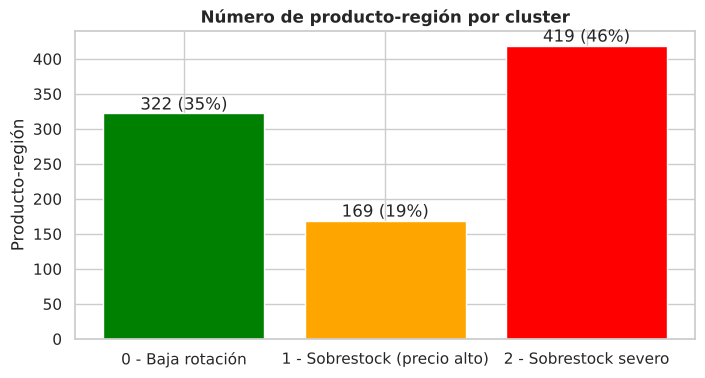

In [ ]:
colores = {'0 - Baja rotación': 'green', '1 - Sobrestock (precio alto)': 'orange', '2 - Sobrestock severo': 'red'}
conteo = df['nombre_cluster'].value_counts().sort_index()
plt.figure(figsize=(8, 4))
barras = plt.bar(conteo.index, conteo.values, color=[colores[n] for n in conteo.index])
plt.bar_label(barras, labels=[f'{v} ({v / len(df):.0%})' for v in conteo.values])
plt.title('Número de producto-región por cluster', fontweight='bold')
plt.ylabel('Producto-región')
plt.show()

El **cluster 2 (sobrestock severo)** es el más grande, con casi la mitad de los producto-región (≈ 46%). Le sigue el **cluster 0 (baja rotación)** con ≈ 35%, y el **cluster 1 (precio alto)** es el más pequeño con ≈ 19%. Es decir, **dos de cada tres producto-región tienen sobrestock**.

### A.10.2 Perfil de cada cluster (mapa de calor)

Para ver de un vistazo qué distingue a cada grupo, grafiqué el promedio de cada variable por cluster en un mapa de calor. Los colores se calcularon con los valores **estandarizados**, para poder comparar variables con escalas distintas: **rojo = valor alto** en comparación con los demás grupos y **azul = valor bajo**. Dentro de cada celda se muestra el valor real. Incluí también las variables que no se usaron para formar los grupos (ventas, cumplimiento y estabilidad), para comprobar que los grupos tienen sentido.

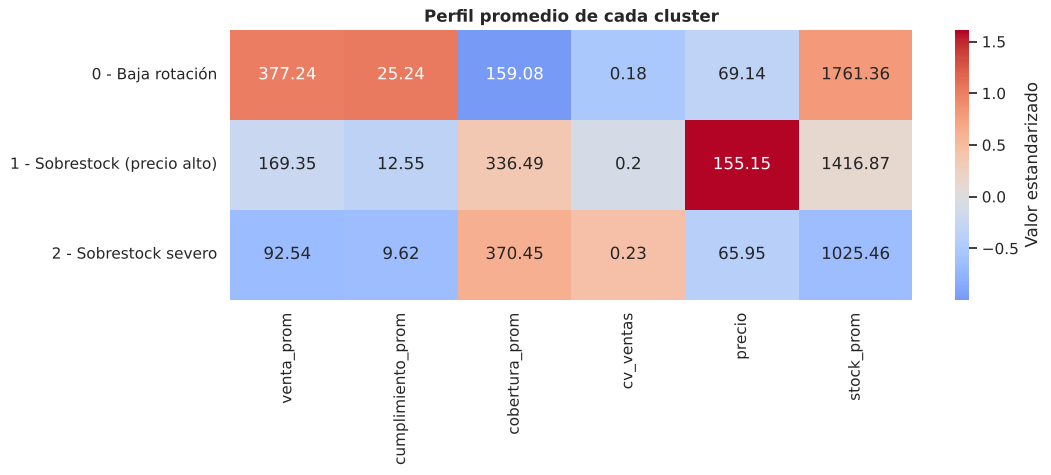

In [ ]:
variables_perfil = ['venta_prom', 'cumplimiento_prom', 'cobertura_prom', 'cv_ventas', 'precio', 'stock_prom']
promedios = df.groupby('nombre_cluster')[variables_perfil].mean()
promedios_z = (promedios - df[variables_perfil].mean()) / df[variables_perfil].std() # qué tan arriba o abajo del promedio general está cada grupo

plt.figure(figsize=(11, 3.5))
sns.heatmap(promedios_z, annot=promedios.round(2), fmt='', cmap='coolwarm', center=0, cbar_kws={'label': 'Valor estandarizado'})
plt.title('Perfil promedio de cada cluster', fontweight='bold')
plt.ylabel('')
plt.show()

- **Cluster 0:** es el único con **ventas y cumplimiento altos** (rojo) y **cobertura baja** (azul). También tiene el **mayor stock** (≈ 1,760) porque son las regiones a las que más inventario se envía. Aunque las ventas no se usaron para formar los grupos, este grupo las tiene claramente más altas, lo que confirma que la cobertura y el stock sí resumen el comportamiento de venta.
- **Cluster 1:** lo que más lo distingue es el **precio alto** (rojo intenso, ≈ 155). Sus ventas, cumplimiento y stock son intermedios y su cobertura está por encima del promedio.
- **Cluster 2:** tiene las **ventas, el cumplimiento y el stock más bajos** (azul), pero la **cobertura más alta** (rojo) y las ventas más inestables (`cv_ventas` alto). Es decir, aunque es el grupo con menos inventario, ese inventario es demasiado para lo poco que vende.

### A.10.3 Distribución de las variables por cluster (boxplots)

Con los boxplots, se puede ver claramente el comportamiento de cada uno de los clusters.

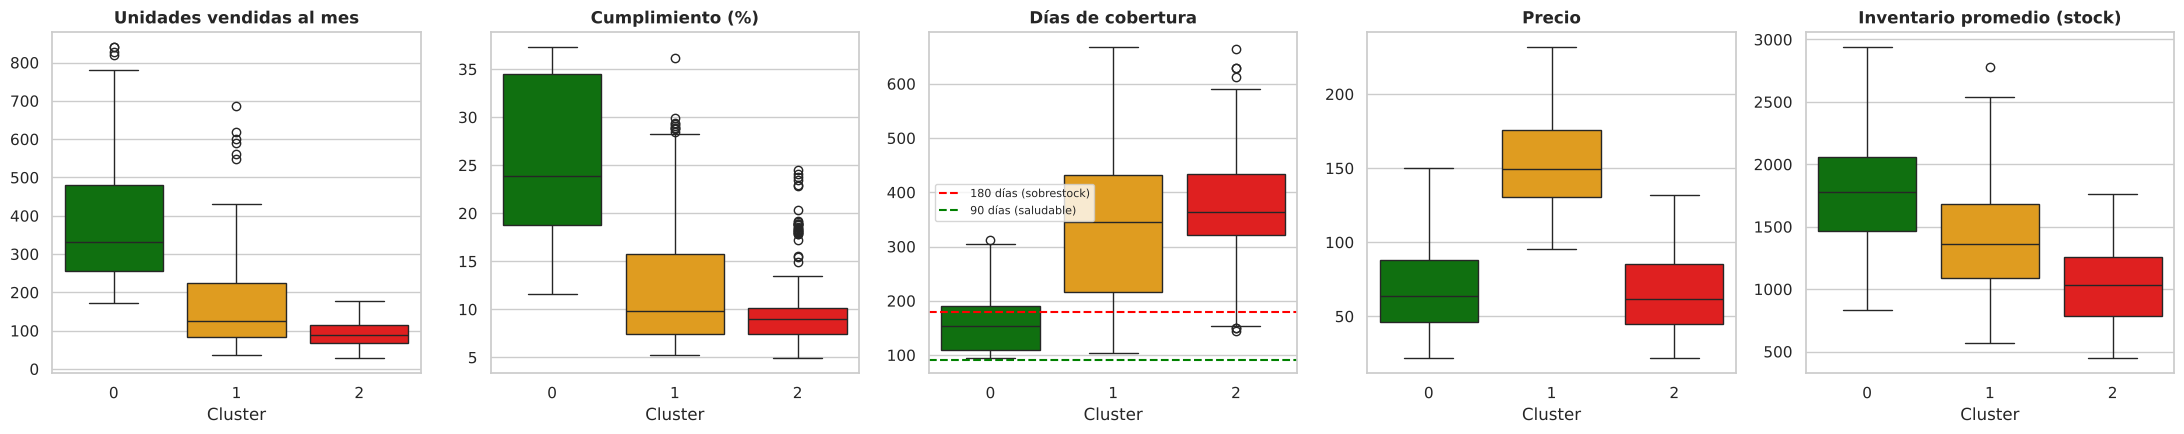

In [ ]:
fig, ax = plt.subplots(1, 5, figsize=(22, 4.5))
titulos = {'venta_prom': 'Unidades vendidas al mes', 'cumplimiento_prom': 'Cumplimiento (%)',
           'cobertura_prom': 'Días de cobertura', 'precio': 'Precio', 'stock_prom': 'Inventario promedio (stock)'}

for i, (variable, titulo) in enumerate(titulos.items()):
    sns.boxplot(data=df, x='cluster', y=variable, hue='nombre_cluster', palette=colores, legend=False, ax=ax[i])
    ax[i].set_title(titulo, fontweight='bold')
    ax[i].set_xlabel('Cluster')
    ax[i].set_ylabel('')
ax[2].axhline(180, color='red', linestyle='--', label='180 días (sobrestock)')
ax[2].axhline(90, color='green', linestyle='--', label='90 días (saludable)')
ax[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

- **Unidades vendidas y cumplimiento:** el cluster 0 está claramente por encima de los otros dos, lo que confirma que es el grupo que mejor vende.
- **Días de cobertura:** **ningún grupo baja de la línea verde de 90 días** (nivel saludable). Casi toda la caja del cluster 0 queda por debajo de los 180 días, la del cluster 2 queda completa por encima, y la del cluster 1 está por encima pero es muy amplia, ya que reúne productos caros de todas las regiones (algunos se venden bien y otros no).
- **Precio:** el cluster 1 tiene precios **mucho más altos** (la mayoría entre ≈ 130 y ≈ 175) que los clusters 0 y 2 (la mayoría entre ≈ 45 y ≈ 88), por lo que es muy fácil de identificar.
- **Inventario:** el cluster 0 tiene el stock más alto y el cluster 2 el más bajo. Esto muestra que el problema no es solo cuánto inventario hay, sino cuánto inventario hay **comparado con lo que se vende**.

### A.10.4 Región y categoría de cada cluster

Revisé qué porcentaje de cada cluster pertenece a cada región y a cada categoría con `pd.crosstab(..., normalize='index')`.

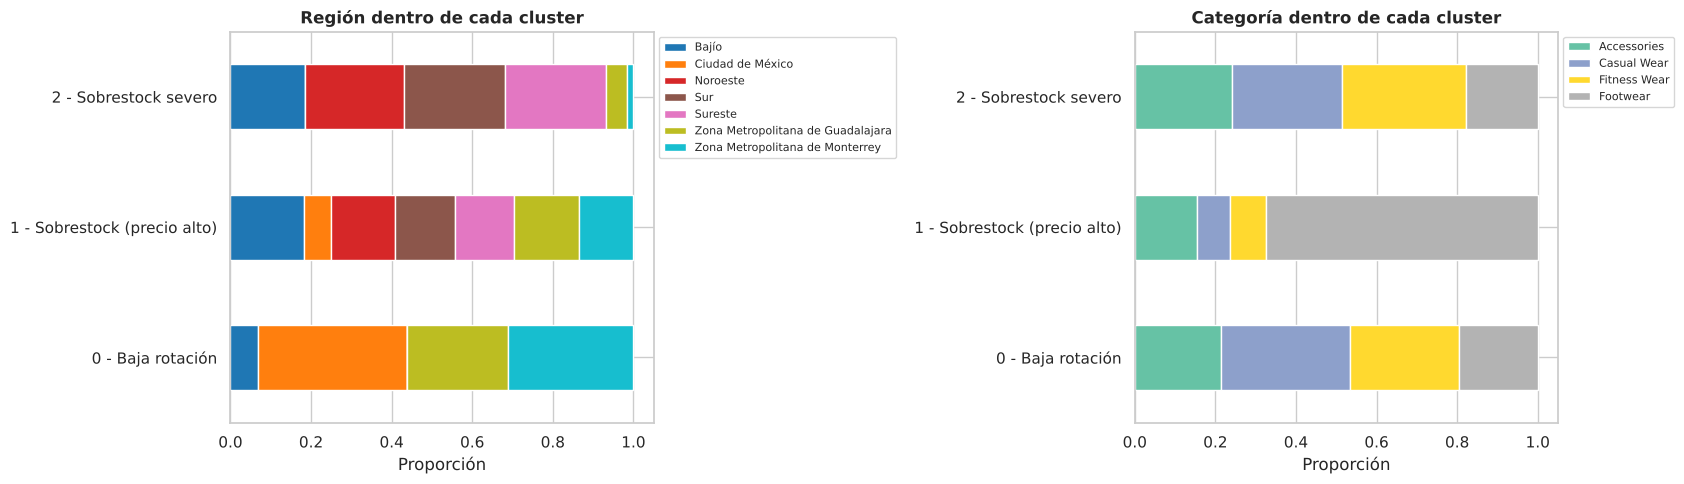


Frecuencia de region por cluster:
cluster                               0     1     2
region                                             
Bajío                             0.070 0.180 0.180
Ciudad de México                  0.370 0.070 0.000
Noroeste                          0.000 0.160 0.250
Sur                               0.000 0.150 0.250
Sureste                           0.000 0.150 0.250
Zona Metropolitana de Guadalajara 0.250 0.160 0.050
Zona Metropolitana de Monterrey   0.310 0.140 0.020

Frecuencia de category por cluster:
cluster          0     1     2
category                      
Accessories  0.210 0.150 0.240
Casual Wear  0.320 0.080 0.270
Fitness Wear 0.270 0.090 0.310
Footwear     0.200 0.670 0.180


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
pd.crosstab(df['nombre_cluster'], df['region'], normalize='index').plot(kind='barh', stacked=True, colormap='tab10', ax=ax[0])
ax[0].set_title('Región dentro de cada cluster', fontweight='bold')
ax[0].set_xlabel('Proporción')
ax[0].set_ylabel('')
ax[0].legend(fontsize=8, bbox_to_anchor=(1, 1))
pd.crosstab(df['nombre_cluster'], df['category'], normalize='index').plot(kind='barh', stacked=True, colormap='Set2', ax=ax[1])
ax[1].set_title('Categoría dentro de cada cluster', fontweight='bold')
ax[1].set_xlabel('Proporción')
ax[1].set_ylabel('')
ax[1].legend(fontsize=8, bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

for var in ['region', 'category']:
    print(f'\nFrecuencia de {var} por cluster:')
    print(pd.crosstab(df['cluster'], df[var], normalize='index').round(2).T)

- **Región:** el **cluster 0** está formado casi solo por **Ciudad de México, Monterrey y Guadalajara** (≈ 93%, el resto es del Bajío), mientras que el **cluster 2** está formado casi solo por **Bajío, Noroeste, Sur y Sureste** (≈ 93%). El **cluster 1** tiene una proporción parecida de todas las regiones (entre 7% y 18%), ya que agrupa a los **productos caros de las 7 regiones**.
- **Categoría:** los clusters 0 y 2 tienen una mezcla parecida de las cuatro categorías, pero el **cluster 1 es 67% Footwear** (botas y sneakers), que son los productos con mayor precio.
- Esto confirma lo encontrado en la etapa 4.3: **la región es lo que más separa a los grupos de precio normal**, mientras que el precio separa a los productos caros sin importar la región.

### A.10.5 Calidad de cada cluster (silueta por observación)

Calculé la silueta de cada producto-región con `silhouette_samples`. Una silueta cercana a 1 indica que el producto-región está bien ubicado en su grupo, y una **negativa** indica que está en la frontera y se parece más a otro grupo.

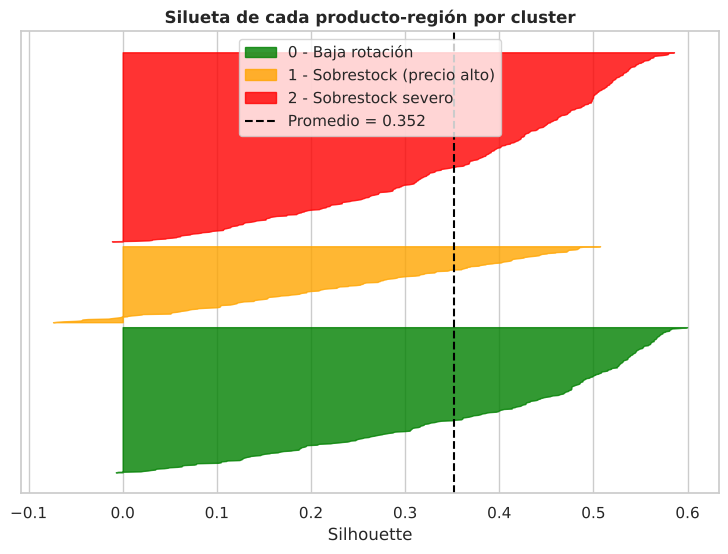

Producto-región con silhouette negativa: 16


,Silueta promedio,Negativas
nombre_cluster,,
0 - Baja rotación,0.387,2
1 - Sobrestock (precio alto),0.243,13
2 - Sobrestock severo,0.370,1


In [ ]:
df['silhouette'] = silhouette_samples(X, df['cluster']) # silueta de cada producto-región
fig, ax = plt.subplots(figsize=(9, 6))
y_inicio = 0
for nombre in sorted(df['nombre_cluster'].unique()):
    valores = np.sort(df.loc[df['nombre_cluster'] == nombre, 'silhouette'])
    ax.fill_betweenx(np.arange(y_inicio, y_inicio + len(valores)), 0, valores, color=colores[nombre], alpha=0.8, label=nombre)
    y_inicio += len(valores) + 10
ax.axvline(df['silhouette'].mean(), color='black', linestyle='--', label=f"Promedio = {df['silhouette'].mean():.3f}")
ax.set_title('Silueta de cada producto-región por cluster', fontweight='bold')
ax.set_xlabel('Silhouette')
ax.set_yticks([])
ax.legend()
plt.show()

print('Producto-región con silhouette negativa:', (df['silhouette'] < 0).sum())
df.groupby('nombre_cluster')['silhouette'].agg(['mean', lambda s: (s < 0).sum()]).rename(columns={'mean': 'Silueta promedio', '<lambda_0>': 'Negativas'})

- El **cluster 0** (silueta promedio ≈ 0.39) y el **cluster 2** (≈ 0.37) son los mejor formados, y casi no tienen valores negativos.
- El **cluster 1** es el menos definido (≈ 0.24) y es donde están casi todos los negativos (13), ya que reúne productos caros con coberturas muy distintas.
- Solo **16 de 910 producto-región (≈ 2%) tienen silueta negativa**, o sea, casi todos están claramente ubicados en su grupo.

### A.10.6 Resumen: ¿qué significa cada cluster?

| Cluster | Nombre | ¿Quiénes son? | Ventas al mes | Cumplimiento | Cobertura | Precio | Stock |
|---|---|---|---|---|---|---|---|
| **0** | Baja rotación (el que mejor rota de los tres, pero no llega a saludable) | CDMX, Monterrey y Guadalajara; productos de precio normal | ≈ 377 | ≈ 25% | ≈ 159 días | ≈ 69 | ≈ 1,761 |
| **1** | Sobrestock de precio alto | Los productos más caros (67% Footwear), en las 7 regiones | ≈ 169 | ≈ 13% | ≈ 336 días | ≈ 155 | ≈ 1,417 |
| **2** | Sobrestock severo | Bajío, Noroeste, Sur y Sureste; productos de precio normal | ≈ 93 | ≈ 10% | ≈ 370 días | ≈ 66 | ≈ 1,025 |

Ningún grupo alcanza una cobertura saludable (menos de 90 días), lo que confirma que el sobreinventario de DanuStore es general. Sin embargo, el problema es mucho más grave en las regiones con menores ventas (cluster 2) y en los productos de precio alto (cluster 1).

## A.11 Visualización con biplot (PCA)

Para ver los grupos en 2D, resumí las 3 variables en 2 componentes con PCA y desarrollé un **biplot**. Cada punto es un producto-región y cada flecha una variable.

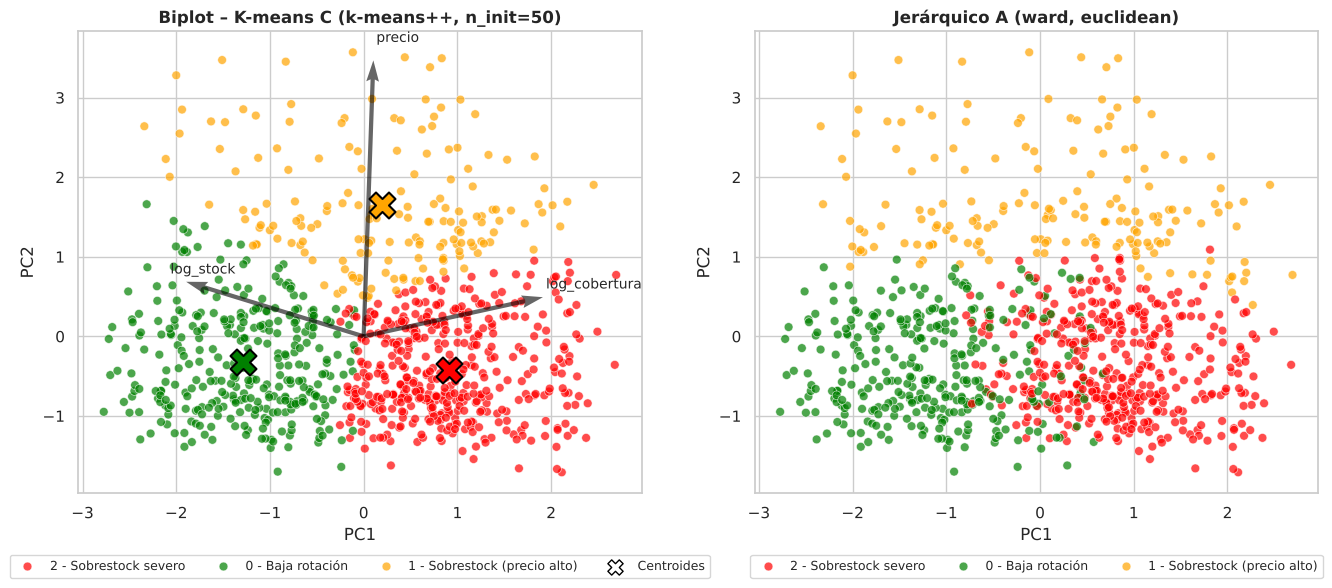

Varianza explicada por PC1 y PC2: 85.0%

Que peso tiene cada variable dentro de cada PC
                 PC1   PC2
log_cobertura  0.710 0.138
precio         0.038 0.972
log_stock     -0.703 0.192


In [ ]:
pca_2d = PCA(n_components=2)
scores = pca_2d.fit_transform(X)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Biplot del mejor modelo (K-means)
sns.scatterplot(x=scores[:, 0], y=scores[:, 1], hue=df['nombre_cluster'], palette=colores, s=40, alpha=0.7, ax=ax[0])
x_arrow = pca_2d.components_[0, :] * scores[:, 0].max()
y_arrow = pca_2d.components_[1, :] * scores[:, 1].max()
ax[0].quiver([0] * len(variables), [0] * len(variables), x_arrow, y_arrow,
             angles='xy', scale_units='xy', scale=1, color='black', alpha=0.6)
textos = [ax[0].text(x, y, var, fontsize=10) for x, y, var in zip(x_arrow * 1.1, y_arrow * 1.1, variables)]
adjust_text(textos, ax=ax[0])
# Centroides de K-means: se proyectan al mismo plano del PCA y se marcan con una X
centroides_2d = pca_2d.transform(kmeans_final.cluster_centers_)
for viejo, (cx, cy) in enumerate(centroides_2d):
    nombre = nombres[list(orden).index(viejo)] # mismo nombre y color que su cluster
    ax[0].scatter(cx, cy, marker='X', s=350, color=colores[nombre], edgecolor='black', linewidth=1.5, zorder=5)
ax[0].scatter([], [], marker='X', s=120, color='white', edgecolor='black', label='Centroides')
ax[0].set_title('Biplot – K-means C (k-means++, n_init=50)', fontweight='bold')
ax[0].set_xlabel('PC1')
ax[0].set_ylabel('PC2')
ax[0].legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=9)

# Mismo plano con los grupos del jerárquico (ordenados igual, por cobertura)
orden_jer = df.assign(c=etiquetas_jerarquico).groupby('c')['cobertura_prom'].mean().sort_values().index
grupos_jer = pd.Series(etiquetas_jerarquico, name='nombre_cluster').map({viejo: nombres[nuevo] for nuevo, viejo in enumerate(orden_jer)})
sns.scatterplot(x=scores[:, 0], y=scores[:, 1], hue=grupos_jer, palette=colores, s=40, alpha=0.7, ax=ax[1])
ax[1].set_title('Jerárquico A (ward, euclidean)', fontweight='bold')
ax[1].set_xlabel('PC1')
ax[1].set_ylabel('PC2')
ax[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=9)
plt.show()

print(f'Varianza explicada por PC1 y PC2: {pca_2d.explained_variance_ratio_.sum():.1%}')

print("\nQue peso tiene cada variable dentro de cada PC")
print(pd.DataFrame(pca_2d.components_.T, index=variables, columns=['PC1', 'PC2']))

- Los dos componentes explican el **85%** de la información de las 3 variables, por lo que la gráfica representa bien los datos.
- Las flechas muestran hacia dónde aumenta cada variable: el **precio** hacia arriba, la **cobertura** hacia la derecha y el **stock** hacia la izquierda.
- Por eso el **cluster 1** (precio alto) queda arriba, el **cluster 0** (mucho stock y poca cobertura) a la izquierda y el **cluster 2** (mucha cobertura) a la derecha.
- En la gráfica del jerárquico, el grupo de precio alto sale casi igual, pero la frontera entre los clusters 0 y 2 está más mezclada, lo que explica el ARI de ≈ 0.66 de la sección A.9.2.

## A.12 Aplicación al Objetivo 1 (Inventario)

Para cada grupo propuse una acción y estimé el **dinero detenido** (inventario que sobra × precio). Como la base no incluye el costo de los productos, utilicé el precio de venta, por lo que el monto es solo una referencia.

In [ ]:
acciones = {0: 'Venta cruzada y frenar nuevas compras',
            1: 'Descuentos dirigidos y traspaso a las zonas metropolitanas',
            2: 'Liquidación y dejar de surtir'}

df['dinero_detenido'] = (df['stock_prom'] - df['venta_prom']).clip(lower=0) * df['precio']
df['accion'] = df['cluster'].map(acciones)

estrategia = df.groupby('cluster').agg(producto_region=('product_id', 'count'), dinero_detenido=('dinero_detenido', 'sum'))
estrategia['% del dinero detenido'] = estrategia['dinero_detenido'] / estrategia['dinero_detenido'].sum() * 100
estrategia['estado'] = perfil['estado']
estrategia['acción'] = estrategia.index.map(acciones)
estrategia

,producto_region,dinero_detenido,% del dinero detenido,estado,acción
cluster,,,,,
0,322,31051795.274,34.667,Baja rotación,Venta cruzada y frenar nuevas compras
1,169,33145899.663,37.005,Sobrestock (precio alto),Descuentos dirigidos y traspaso a las zonas metropolitanas
2,419,25373839.491,28.328,Sobrestock severo,Liquidación y dejar de surtir


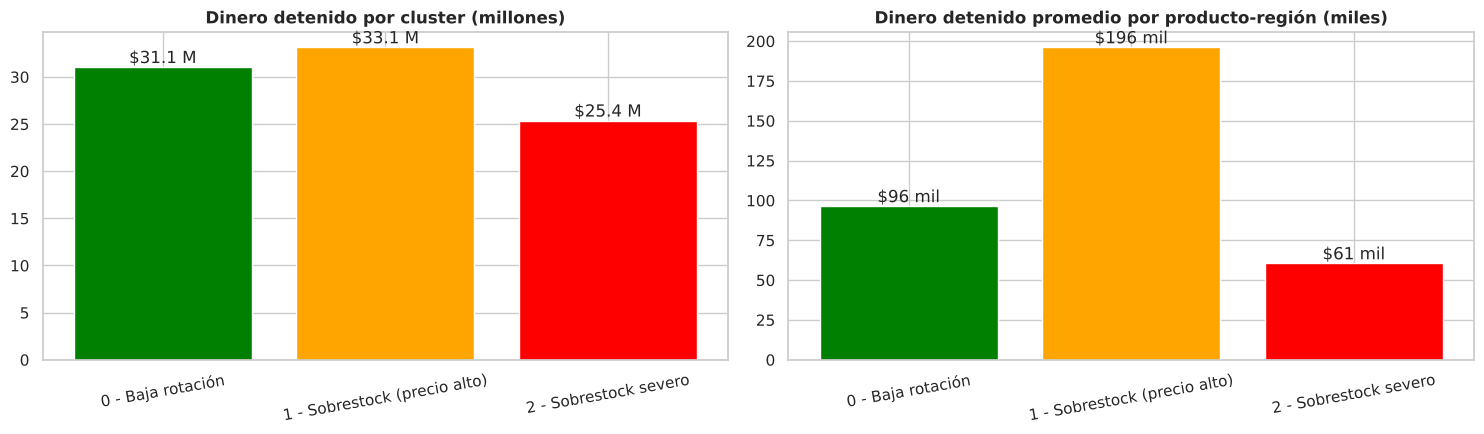

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))

# Dinero detenido total por cluster
dinero = df.groupby('nombre_cluster')['dinero_detenido'].sum() / 1e6
barras = ax[0].bar(dinero.index, dinero.values, color=[colores[n] for n in dinero.index])
ax[0].bar_label(barras, labels=[f'${v:.1f} M' for v in dinero.values])
ax[0].set_title('Dinero detenido por cluster (millones)', fontweight='bold')
ax[0].tick_params(axis='x', rotation=10)

# Dinero detenido promedio por producto-región
promedio = df.groupby('nombre_cluster')['dinero_detenido'].mean() / 1e3
barras = ax[1].bar(promedio.index, promedio.values, color=[colores[n] for n in promedio.index])
ax[1].bar_label(barras, labels=[f'${v:.0f} mil' for v in promedio.values])
ax[1].set_title('Dinero detenido promedio por producto-región (miles)', fontweight='bold')
ax[1].tick_params(axis='x', rotation=10)

plt.tight_layout()
plt.show()

- En **total**, el **cluster 1 (precio alto)** es el que más dinero tiene detenido (≈ 37%), a pesar de ser el grupo más pequeño, ya que cada pieza vale más del doble.
- **Por cada producto-región**, la diferencia es todavía mayor: el cluster 1 tiene ≈ 196 mil detenidos en promedio, el doble que el cluster 0 y más del triple que el cluster 2. Por ello, es donde los descuentos y traspasos tienen mayor impacto económico.
- El **cluster 0**, aunque es el de mejor rotación, también tiene mucho dinero detenido (≈ 35%), ya que las zonas metropolitanas reciben los inventarios más grandes.

## A.13 Conclusiones de la Parte A

- **Variables:** con las correlaciones y el PCA identifiqué que varias variables repetían información, por lo que utilicé 3 variables que dicen cosas distintas: la cobertura (qué tan lento se vende el inventario), el precio (cuánto vale cada pieza) y el stock (qué tan grande es el inventario). Así el inventario forma parte del modelo y ninguna idea se cuenta dos veces. Las demás variables las utilicé para interpretar los grupos.
- **Hiperparámetros:** en cada modelo utilicé 3 hiperparámetros con 3 ajustes. En K-means (`n_clusters`, `init`, `n_init`) los tres ajustes dieron casi el mismo resultado, y seleccioné el ajuste C (`init='k-means++'`, `n_init=50`) porque tuvo la silueta más alta y fue el único que dio exactamente el mismo resultado con las 10 semillas. En el jerárquico (`t`, `method`, `metric`) el mejor fue el ajuste A (`method='ward'`, `metric='euclidean'`).
- **Mejor modelo:** **K-means con 3 grupos** (silueta ≈ 0.352, Davies-Bouldin ≈ 1.03), por encima del jerárquico ward (≈ 0.328). Ambos encontraron grupos parecidos (ARI ≈ 0.66), y solo el 2% de los producto-región quedó en la frontera entre grupos.
- **Interpretación:** los grupos separan (0) los producto-región de mejor rotación y mayor inventario en las tres zonas metropolitanas, (1) los productos de precio alto (principalmente Footwear) con sobrestock en todas las regiones, y (2) los de baja venta y sobrestock severo en Bajío, Noroeste, Sur y Sureste.
- **Objetivo 1:** esto permite aplicar una estrategia distinta a cada grupo: venta cruzada en las zonas metropolitanas, descuentos y traspasos para los productos de precio alto (donde está la mayor parte del dinero detenido), y liquidación en las regiones con menores ventas.


---
# PARTE B · Modelos de Clasificación: Árbol de Decisión y Red Neuronal


**Problemática a analizar:** Pronosticar el nivel de sobrestock de los próximos 3 meses (equivalente a t+1, t+2, t+3) de cada combinación producto y región, usando solo la información disponible en el mes actual.

**Variable objetivo: Nivel de Inventario en Meses**, medido con cuatro clases: Bajo, Medio, Alto, Crítico

**Modelos Utilizados:** Árbol de Decisión y Red Neuronal (MLP).


## B.1 Librerías y Google Drive

Las librerías de esta parte (`statsmodels`, `chi2_contingency`, `DecisionTreeClassifier`, `MLPClassifier`, `GridSearchCV`, métricas de clasificación, etc.), las constantes `RANDOM_STATE = 42`, `NIVELES` y `COLORES`, y la conexión con Google Drive ya se cargaron en la **sección 0**.

## B.2 Importación de datos

Para este análisis, se da prioridad al dataset **mensual** con el que cuenta el equipo (ya cargado en la sección 0), que engloba 7 regiones × 130 productos × 24 meses (2024–2025).

In [ ]:
# data_DanuStore_Mensual se cargó en la sección 0; la base diaria se lee en el anexo B.11
pd.reset_option("display.float_format")   # la Parte A fijó 3 decimales; la Parte B usa el formato por defecto

df = data_DanuStore_Mensual.copy()
print("Filas: ", df.shape[0])
print("Columnas: ", df.shape[1])
display(df.head())

Filas:  21840
Columnas:  20


,month,year,product_id,region,units_expected,stock,percentage,units_sold,sales_amount,product_name,category,subcategory,static_price,inventory_key,Ventas_Acumuladas_Mensual,Stock_Restante_Mensual,Cumplimiento_Venta_Esperada,Product_Repeat_Purchase_Rate,Venta_Promedio_Diaria,Dias_Cobertura_Inventario
0,March,2025,39,Bajío,1057,1735,164.14,107,4045.32,Shirts Product 39,Casual Wear,Shirts,45.40,Bajío_39_March_2025,107,1628,10.12,99.92,3.451613,502.66
1,October,2025,46,Ciudad de México,1983,3215,162.13,671,49978.14,Pants Product 46,Casual Wear,Pants,87.10,Ciudad de México_46_October_2025,671,2544,33.84,99.89,21.645161,148.53
2,May,2025,113,Ciudad de México,2549,4030,158.10,693,52325.53,Boots Product 113,Footwear,Boots,88.06,Ciudad de México_113_May_2025,693,3337,27.19,99.88,22.354839,180.27
3,February,2025,75,Ciudad de México,1388,2192,157.93,355,23911.75,Jewelry Product 75,Accessories,Jewelry,79.43,Ciudad de México_75_February_2025,355,1837,25.58,99.84,12.678571,172.89
4,October,2025,84,Ciudad de México,1458,2298,157.61,467,18204.74,Hats Product 84,Accessories,Hats,44.88,Ciudad de México_84_October_2025,467,1831,32.03,99.78,15.064516,152.54


## B.3 Exploración y selección de variables  *(Rúbrica: Exploración y análisis inicial)*

### B.3.1 Universo de variables
Regla: Para el modelo, **solo entra lo que se conoce antes de vender.** Por ejemplo, todas las variables que se calculan a partir de `units_sold` son **variables de salida**, y usarlas representaría caer en fuga de datos.

| Variable | Tipo | ¿Se conoce antes de vender? | Rol |
|---|---|---|---|
| `month` / `year` | Temporal | Sí | Predictora: mes como número (1–12). `year` solo ordena la serie en el tiempo |
| `region` | Categórica | Sí | Predictora |
| `category` / `subcategory` | Categórica | Sí | Predictora (`subcategory`) |
| `units_expected` | Numérica | Sí (pronóstico) | Predictora |
| `stock` | Numérica | Sí | Candidata → se evalúa VIF |
| `percentage` = stock / expected | Numérica | Sí | Predictora |
| `static_price` | Numérica | Sí | Predictora |
| `product_id` / `product_name` / `inventory_key` | ID | — | Excluida (identificador) |
| `Product_Repeat_Purchase_Rate` | Numérica | Constante por producto | Excluida (sin variación) |
| `units_sold` | Numérica | **NO** (resultado) | Excluida (salida) |
| `Ventas_Acumuladas_Mensual` | Numérica | **NO** (= units_sold) | Excluida (salida) |
| `sales_amount` | Numérica | **NO** | Excluida (salida) |
| `Stock_Restante_Mensual` | Numérica | **NO** (stock − vendido) | Excluida (salida) |
| `Cumplimiento_Venta_Esperada` | Numérica | **NO** (vendido / esperado) | Excluida (salida) |
| `Venta_Promedio_Diaria` | Numérica | **NO** (vendido / días) | Excluida (salida) |
| `Dias_Cobertura_Inventario` | Numérica | **NO** | Solo para construir el objetivo |

### B.3.2 Comprobación de fuga: las variables de salida se derivan de `units_sold`

In [ ]:
dias_mes = pd.to_datetime(df["month"] + " " + df["year"].astype(str), format="%B %Y").dt.days_in_month
chequeo = {
    "Ventas_Acumuladas = units_sold":        (df["Ventas_Acumuladas_Mensual"] - df["units_sold"]).abs().max(),
    "Stock_Restante = stock − units_sold":    (df["stock"] - df["units_sold"] - df["Stock_Restante_Mensual"]).abs().max(),
    "Cumplimiento = units_sold/expected·100": (df["units_sold"] / df["units_expected"] * 100 - df["Cumplimiento_Venta_Esperada"]).abs().max(),
    "Venta_Prom_Diaria = units_sold/días":    (df["units_sold"] / dias_mes - df["Venta_Promedio_Diaria"]).abs().max(),
    "percentage = stock/expected·100":        (df["stock"] / df["units_expected"] * 100 - df["percentage"]).abs().max(),
}
pd.Series(chequeo, name="Error máximo").round(3).to_frame()

,Error máximo
Ventas_Acumuladas = units_sold,0.000
Stock_Restante = stock − units_sold,0.000
Cumplimiento = units_sold/expected·100,0.005
Venta_Prom_Diaria = units_sold/días,0.000
percentage = stock/expected·100,0.005


### B.3.3 Hallazgo: el indicador de stock que utiliza DanuStore NO detecta el sobrestock real

DanuStore mide su inventario con la variable de `percentage` (stock ÷ unidades esperadas). Por eso, lo comparo con los **meses de inventario reales** (cuánto tardaría en venderse el stock al ritmo presentado de las ventas).

Ventas reales vs esperadas: se vende en promedio el 15.7% de lo esperado
Stock vs ventas reales (mediana): 875%
Meses de inventario (mediana): 8.8 | Registros con ≤ 3 meses: 2.9%



meses_inv,Bajo,Medio,Alto,Crítico
percentage,,,,
≤105% (normal),0.15,0.21,0.36,0.28
105–120%,0.28,0.24,0.21,0.28
>120% (muy alto),0.36,0.33,0.14,0.17


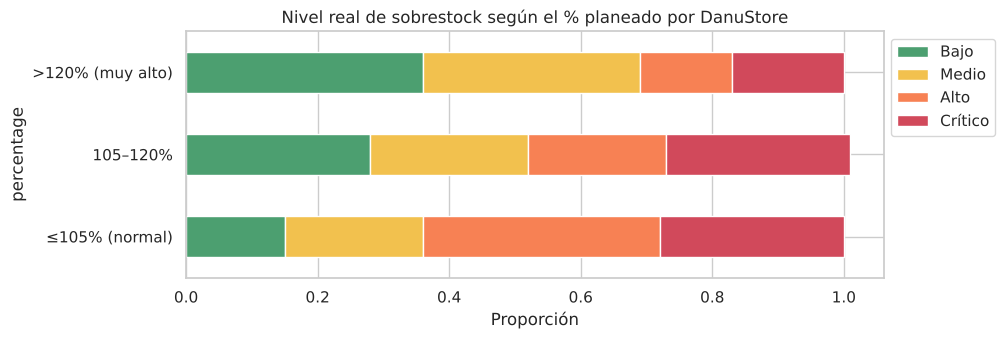

In [ ]:
df["meses_inv"] = df["Dias_Cobertura_Inventario"] / 30.4
print(f"Ventas reales vs esperadas: se vende en promedio el {df['Cumplimiento_Venta_Esperada'].mean():.1f}% de lo esperado")
print(f"Stock vs ventas reales (mediana): {(df['stock'] / df['units_sold'] * 100).median():.0f}%")
print(f"Meses de inventario (mediana): {df['meses_inv'].median():.1f} | Registros con ≤ 3 meses: {(df['meses_inv'] <= 3).mean():.1%}")
print('')

banda_pct = pd.cut(df["percentage"], [0, 105, 120, np.inf], labels=["≤105% (normal)", "105–120%", ">120% (muy alto)"])
cuartil_real = pd.qcut(df["meses_inv"], 4, labels=NIVELES)
tabla_pct = pd.crosstab(banda_pct, cuartil_real, normalize="index").round(2)
display(tabla_pct)
print('')

tabla_pct.plot.barh(stacked=True, color=COLORES, figsize=(9, 3.2))
plt.title("Nivel real de sobrestock según el % planeado por DanuStore"); plt.xlabel("Proporción")
plt.legend(bbox_to_anchor=(1, 1)); plt.show()

**Lectura:** los productos con `percentage` "normal" (≤105%) terminan con **más** sobrestock crítico que los de >120%. El pronóstico `units_expected` sobreestima la demanda real aproximadamente unas 6 veces, así que el % planeado realmente no sirve para detectar el sobrestock. Por eso hace falta un modelo.

**De aquí nace la necesidad de hacer un modelo.**

### B.3.4 ¿Número de clases? Complemento con K-Means

De acuerdo a la investigación que propongo, propuse de inicio 4 clases, que son los respectivos niveles de bajo a crítico. No obstante, es importante **respaldar con datos**. Por esa misma razón, utilizo K-Means únicamente para **explorar** cuántos grupos naturales tiene la data de los meses de inventario.

NOTA: No es uno de los modelos evaluados en esta parte, solo un complemento (los modelos de clustering se comparan a fondo en la Parte A). Se aplica sobre `log(meses_inv)`, porque la distribución tiene cola larga.

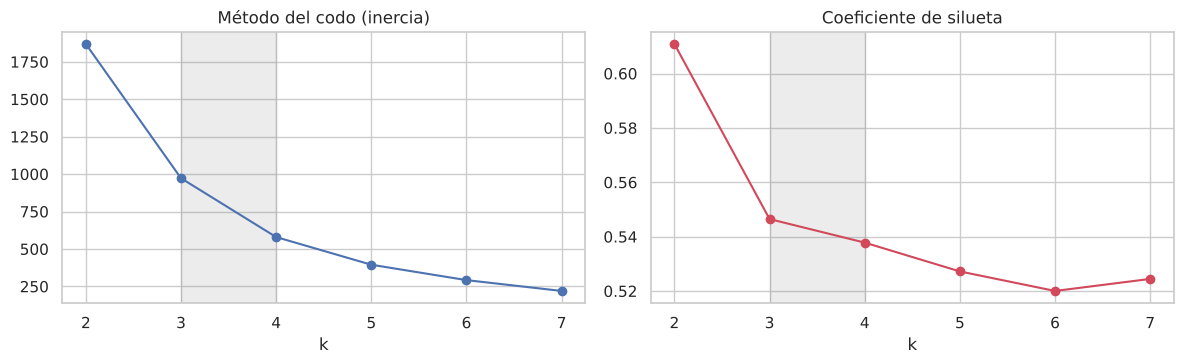

Centros K-Means (k=4) en meses: [ 3.7  6.3 10.5 16.6]
Cortes por cuartiles en meses:   [5.4, 8.8, 12.6]


In [ ]:
Z = np.log(df[["meses_inv"]].values)
ks, inercia, silueta = range(2, 8), [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(Z, km.labels_, sample_size=6000, random_state=RANDOM_STATE))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(ks, inercia, "o-"); ax[0].set_title("Método del codo (inercia)"); ax[0].set_xlabel("k")
ax[1].plot(ks, silueta, "o-", color="#D1495B"); ax[1].set_title("Coeficiente de silueta"); ax[1].set_xlabel("k")
for a in ax: a.axvspan(3, 4, color="gray", alpha=0.15)
plt.tight_layout(); plt.show()

km4 = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(Z)
centros = np.sort(np.exp(km4.cluster_centers_.ravel()))
print("Centros K-Means (k=4) en meses:", centros.round(1))
print("Cortes por cuartiles en meses:  ", df["meses_inv"].quantile([.25, .5, .75]).round(1).tolist())

Como se puede observar en las gráficas del análisis con K-Means, en realidad **el valor de K más óptimo es de 2**. No obstante, optando por incluir una visión de negocio, ¿realmente dos clases me da valor para medir el stock? A mi propio juicio, mantener un modelo binario no ayudaría mucho a la situación de DanuStore, pues solamente se recae en clase "Normal" o "Sobrestock", y lo que realmente se busca es tener un mayor nivel de detalle.

Posteriormente, el análisis coloca a k = 3 y k = 4 en segundo y tercer lugar, agregando un mejor nivel de detalle a las clases. Si bien 3 tiene mejores resultados, puede llegar a unir alto y crítico, lo que al final, también es algo que se mantiene muy general, pues, al final, si un producto se encontrara en un nivel donde no puedes aumentarle más stock, y otro, que apenas y está acumulado su sobrestock, ¿cómo los diferencias si ambos son "Alto"?

Por eso mismo, respaldo mi decisión de las cuatro clases, que mantiene un nivel de detalle suficientemente entendible, al mismo tiempo que mantiene un nivel de clases generales.


### B.3.5 Variable objetivo: Nivel de sobrestock del próximo trimestre (t+1, t+2, t+3).

Una vez definidas las cuatro clases, el siguiente paso es decidir **qué es exactamente lo que el modelo va a predecir**. Para ello, convierto los meses de inventario en niveles usando los **cuartiles** de los datos, lo que me da los cortes de **Bajo · Medio · Alto · Crítico**, con aproximadamente un 25% de los registros en cada clase. De esta forma, evito crear clases desbalanceadas.

No obstante, ¿de qué le sirve a DanuStore saber cómo está su inventario **hoy**, si ya no puede hacer nada al respecto? Lo que realmente aporta valor es **el poder anticiparse**. Por eso mismo, para cada combinación región × producto, la fila del mes *t* recibe como objetivo el **promedio de los meses de inventario de t+1, t+2 y t+3**, clasificado con esos mismos cortes. En otras palabras, el modelo **se entrena con 24 meses de historia**, pero **pronostica el comportamiento de los 3 meses siguientes**.

Opté por promediar el trimestre completo en lugar de predecir un solo mes, ya que esto **suaviza el ruido** que puede tener un mes aislado y le da a la empresa una visión más estable para tomar decisiones de compra o redistribución.

NOTA: Los últimos 3 meses de cada serie se descartan, pues no cuentan con un trimestre futuro completo contra el cual comparar.

Cortes (meses de inventario): {'Bajo': '≤5.4', 'Medio': '5.4–8.8', 'Alto': '8.8–12.6', 'Crítico': '>12.6'}
Registros para modelar: 19110


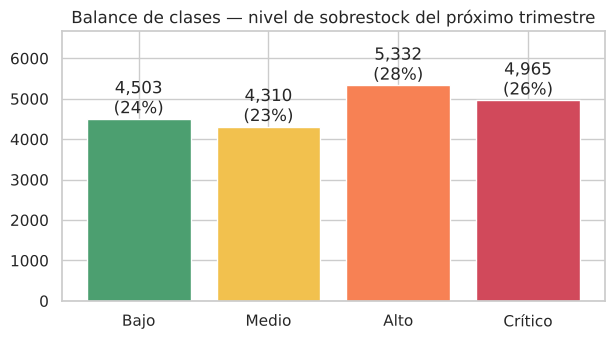

In [ ]:
cortes = df["meses_inv"].quantile([.25, .5, .75]).values
df["nivel"] = pd.cut(df["meses_inv"], [-np.inf, *cortes, np.inf], labels=False)

mes_map = {m: i for i, m in enumerate(["January","February","March","April","May","June","July",
                                        "August","September","October","November","December"], 1)}
df["mes"] = df["month"].map(mes_map)
df["t"] = (df["year"] - 2024) * 12 + df["mes"]
df = df.sort_values(["region", "product_id", "t"]).reset_index(drop=True)
g = df.groupby(["region", "product_id"])["meses_inv"]
for h in [1, 2, 3]:
    df[f"meses_t{h}"] = g.shift(-h)
    df[f"nivel_t{h}"] = pd.cut(df[f"meses_t{h}"], [-np.inf, *cortes, np.inf], labels=False)
df["meses_trim"] = df[["meses_t1", "meses_t2", "meses_t3"]].mean(axis=1, skipna=False)
df["nivel_obj"] = pd.cut(df["meses_trim"], [-np.inf, *cortes, np.inf], labels=False)

d = df.dropna(subset=["nivel_obj"]).copy()
d["nivel_obj"] = d["nivel_obj"].astype(int)
print("Cortes (meses de inventario):", {f"{a}": f"{b}" for a, b in zip(NIVELES, [f"≤{cortes[0]:.1f}", f"{cortes[0]:.1f}–{cortes[1]:.1f}", f"{cortes[1]:.1f}–{cortes[2]:.1f}", f">{cortes[2]:.1f}"])})
print("Registros para modelar:", d.shape[0])

conteo = d["nivel_obj"].value_counts().sort_index()
plt.figure(figsize=(7, 3.5))
plt.bar(NIVELES, conteo.values, color=COLORES)
for i, v in enumerate(conteo.values): plt.text(i, v, f"{v:,}\n({v/len(d):.0%})", ha="center", va="bottom")
plt.ylim(0, conteo.max() * 1.25); plt.title("Balance de clases — nivel de sobrestock del próximo trimestre"); plt.show()

Como se puede observar, las cuatro clases (cuartiles) quedan balanceadas: cada una tiene entre 23% y 28% de los registros (los cortes son los cuartiles de los 21,840 registros; al promediar el trimestre y descartar los últimos 3 meses de cada serie, las proporciones cambian un poco).

### B.3.6 Correlaciones de las variables numéricas candidatas con el objetivo (Pearson)

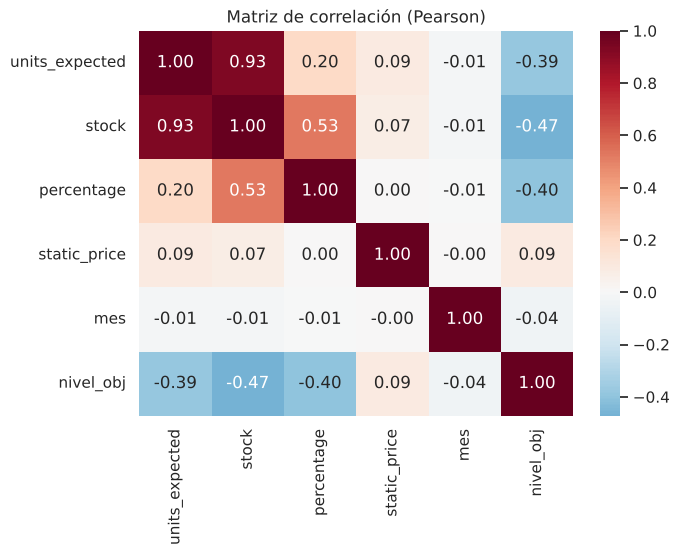

In [ ]:
num_cand = ["units_expected", "stock", "percentage", "static_price", "mes"]
plt.figure(figsize=(7, 5))
sns.heatmap(d[num_cand + ["nivel_obj"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Matriz de correlación (Pearson)"); plt.show()

**Hallazgos de la correlación:**

- `stock` ↔ `units_expected`: **0.93** (multicolinealidad)
- `stock` ↔ nivel de sobrestock: **-0.47**
- `percentage` ↔ nivel de sobrestock: **-0.40**
- `units_expected` ↔ nivel de sobrestock: **-0.39**
- `static_price` (0.09) y `mes` (-0.04): casi sin relación lineal

La alta relación entre `stock` y `units_expected` anticipa la multicolinealidad que confirmo con el VIF. Lo curioso es que **más stock se asocia con menos sobrestock**: los productos con más inventario están en las regiones que más venden (CDMX, Monterrey), lo que refuerza el hallazgo de la sección B.3.3 (y coincide con el cluster 0 de la Parte A). Ninguna variable pasa de ±0.5, por lo que se necesita un modelo que **combine** varias. El mes se conserva porque su efecto es estacional, no lineal, y el Chi² lo marca como significativo.

### B.3.7 Multicolinealidad (VIF)
La evalúo de acuerdo a la escala vista en clase, que es VIF ≈ 1 aceptable · 1–5 moderado · > 5 problema · > 10 muy problemático.

In [ ]:
def tabla_vif(cols):
    Z = sm.add_constant(d[cols])
    return pd.Series({c: variance_inflation_factor(Z.values, i) for i, c in enumerate(Z.columns) if c != "const"})

pd.concat([tabla_vif(["units_expected", "stock", "percentage", "static_price"]).rename("VIF con stock"),
           tabla_vif(["units_expected", "percentage", "static_price"]).rename("VIF sin stock")], axis=1).round(1)

,VIF con stock,VIF sin stock
units_expected,48.6,1.1
stock,64.5,NaN
percentage,9.1,1.0
static_price,1.0,1.0


Como decisión final, dejo de incluir la variable `stock` (VIF ≈ 64.5, *muy problemático* → todos ≈ 1, *aceptable*). La información no se pierde, porque `stock = percentage × units_expected`, y esas variables ya las estoy incluyendo.

### B.3.8 Variables categóricas vs nivel del próximo trimestre (Chi²)

,Variable,Chi²,gl,p-valor
0,region,32372.9,18,0.000000e+00
1,category,501.1,9,3.411244e-102
2,subcategory,939.4,36,8.007906e-174
3,month,356.5,33,6.226140e-56


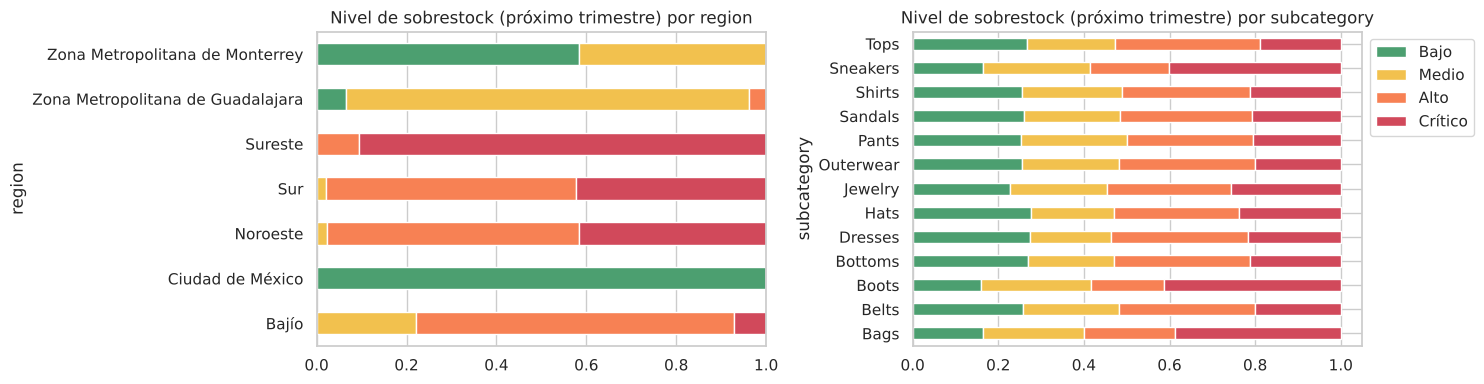

In [ ]:
chi = []
for c in ["region", "category", "subcategory", "month"]:
    chi2, p, dof, _ = chi2_contingency(pd.crosstab(d[c], d["nivel_obj"]))
    chi.append((c, round(chi2, 1), dof, p))
display(pd.DataFrame(chi, columns=["Variable", "Chi²", "gl", "p-valor"]))

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for a, col in zip(ax, ["region", "subcategory"]):
    pd.crosstab(d[col], d["nivel_obj"].map(dict(enumerate(NIVELES))), normalize="index")[NIVELES].plot.barh(
        stacked=True, color=COLORES, ax=a, legend=(col == "subcategory"))
    a.set_title(f"Nivel de sobrestock (próximo trimestre) por {col}")
ax[1].legend(bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()

`subcategory` está anidada en `category`, así que conservamos **subcategory**.
### B.3.9 Variables finales y relevancia (ANOVA F-score, `SelectKBest`)

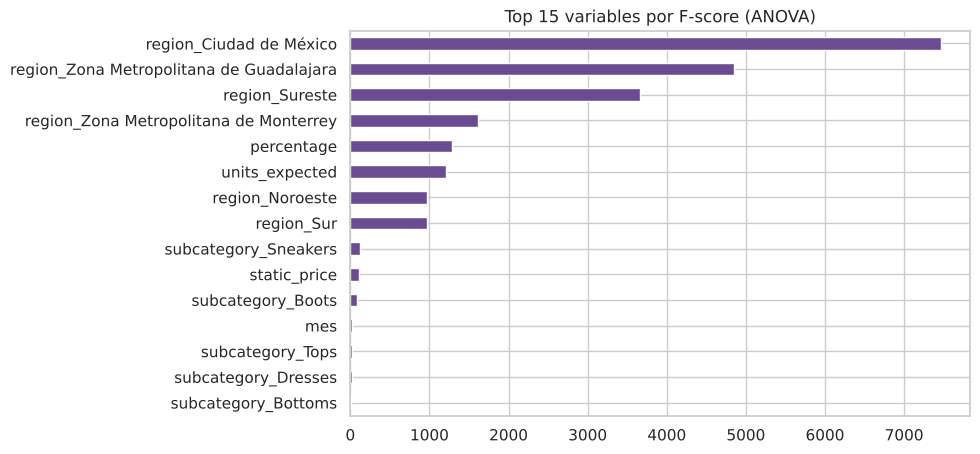

In [ ]:
NUM = ["units_expected", "percentage", "static_price", "mes"]
CAT = ["region", "subcategory"]
X = pd.get_dummies(d[NUM + CAT], columns=CAT, drop_first=True).astype(float)
y = d["nivel_obj"]

fscore = pd.Series(SelectKBest(f_classif, k="all").fit(X, y).scores_, index=X.columns).sort_values()
fscore.tail(15).plot.barh(figsize=(8, 5), color="#6A4C93"); plt.title("Top 15 variables por F-score (ANOVA)"); plt.show()

## B.4 Preprocesamiento
| Paso | Qué se hizo | Por qué |
|---|---|---|
| Codificación | One-hot de `region` y `subcategory` (`drop_first=True`) | Los modelos solo aceptan números; evita redundancia y se convierten las categóricas a numéricas. |
| Mes | Se usa como número (1–12) | Captura la estacionalidad de forma simple. |
| Multicolinealidad | Se eliminó la variable `stock` | VIF ≈ 64.5 → ≈ 1 |
| Estandarización | `StandardScaler` **únicamente en la Red Neuronal**, dentro de un `Pipeline`. | La MLP aprende con descenso de gradiente y es sensible a la escala. El árbol, al dividir por umbrales, no la necesita. Por medio del `Pipeline`, el escalador se ajusta **solo con el entrenamiento.** |
| Balance | Cuartiles (25% por clase) | Sin clases minoritarias y sin remuestreo |

In [ ]:
Xtr_demo, Xte_demo, ytr_demo, yte_demo = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
sc = StandardScaler().fit(Xtr_demo[NUM])
display(pd.concat({"Antes": Xtr_demo[NUM].describe().loc[["mean", "std"]],
                   "Después de StandardScaler": pd.DataFrame(sc.transform(Xtr_demo[NUM]), columns=NUM).describe().loc[["mean", "std"]]}).round(2))

imp = {}
for nombre, modelo in {
    "MLP sin estandarizar": MLPClassifier(hidden_layer_sizes=(32,), max_iter=500, early_stopping=True, random_state=RANDOM_STATE),
    "MLP con StandardScaler": Pipeline([("scaler", StandardScaler()),
                                        ("mlp", MLPClassifier(hidden_layer_sizes=(32,), max_iter=500, early_stopping=True, random_state=RANDOM_STATE))]), }.items():
    pred = modelo.fit(Xtr_demo, ytr_demo).predict(Xte_demo)
    imp[nombre] = {"Accuracy": accuracy_score(yte_demo, pred), "F1 macro": f1_score(yte_demo, pred, average="macro")}

print("Impacto de la estandarización en la Red Neuronal (80/20):")
pd.DataFrame(imp).T.round(3)

units_expected  percentage  static_price   mes
Antes                     mean         1218.58      109.90         83.78  5.87
                          std           434.27       16.65         44.54  3.20
Después de StandardScaler mean           -0.00       -0.00          0.00  0.00
                          std             1.00        1.00          1.00  1.00

Impacto de la estandarización en la Red Neuronal (80/20):


,Accuracy,F1 macro
MLP sin estandarizar,0.804,0.805
MLP con StandardScaler,0.810,0.813


## B.5 Hiperparámetros: qué controlan y por qué estos valores

Recordando que un hiperparámetro es lo que permite controlar la complejidad del modelo, pues con mucha complejidad se cae en "Overfitting" y poca "Underfitting", estos hiperparámetros permiten encontrar el punto intermedio, y no caer en ninguno de estos dos fenómenos.

### B.5.1 Árbol de Decisión

| Hiperparámetro | Qué controla | Valores probados | Por qué |
|---|---|---|---|
| `max_depth` | Número máximo de preguntas en cadena | 4, 6, 8, 10, 12 | Con 4 no alcanza a separar regiones y subcategorías; arriba de 12 solo crece la brecha (ver B.5.4) |
| `min_samples_leaf` | Mínimo de registros por hoja | 10, 25, 50, 100 | Cada regla se apoya en suficientes casos (~0.1%–0.8% del train) |
| `criterion` | Medida de pureza de cada división | gini, entropy | Los dos criterios estándar; se deja que los datos elijan |

### B.5.2 Red Neuronal (MLP)

| Hiperparámetro | Qué controla | Valores probados | Por qué |
|---|---|---|---|
| `hidden_layer_sizes` | Neuronas y capas ocultas (capacidad) | (16,), (32,), (64,), (32, 16), (100,) | De ≈ 0.7 a ≈ 4.5 veces las 22 entradas (4 numéricas + 6 de región + 12 de subcategoría); una vs dos capas; (100,) es el valor por defecto |
| `alpha` | Regularización (castiga pesos grandes) | 0.0001, 0.001, 0.01, 0.1 | Del valor por defecto a una regularización fuerte |
| `learning_rate_init` | Tamaño del paso de aprendizaje | 0.001, 0.01 | El valor por defecto y uno más rápido |

**Fijos:** `relu` y `adam` (estándar), `early_stopping=True` (detiene el entrenamiento cuando deja de mejorar, como freno al overfitting) y `max_iter=500`.

**Criterio de selección:**
1. `GridSearchCV` en cada división (3 folds sobre train), maximizando **F1 macro**.
2. Se elige **una sola configuración por modelo**: la de mejor F1 promedio en las 3 divisiones, y se usa igual en las tres.
3. Se verifica que la **brecha train–test sea ≤ 5 puntos**.

### B.5.3 Comparación justa entre los dos modelos

Aunque sus hiperparámetros son distintos, ambos modelos se evalúan **en igualdad de condiciones**: mismas variables, particiones, validación cruzada, métrica y **40 combinaciones cada uno**, con la misma estructura:

| Rol | Árbol | Red Neuronal | Nº de valores |
|---|---|---|---|
| Capacidad | `max_depth` | `hidden_layer_sizes` | 5 |
| Freno al overfitting | `min_samples_leaf` | `alpha` | 4 |
| Ajuste fino | `criterion` | `learning_rate_init` | 2 |

### B.5.4 Curvas de validación: underfitting vs overfitting (partición 80/20)
Se mueve **un hiperparámetro a la vez** y se compara el F1 macro de train con el de validación cruzada.

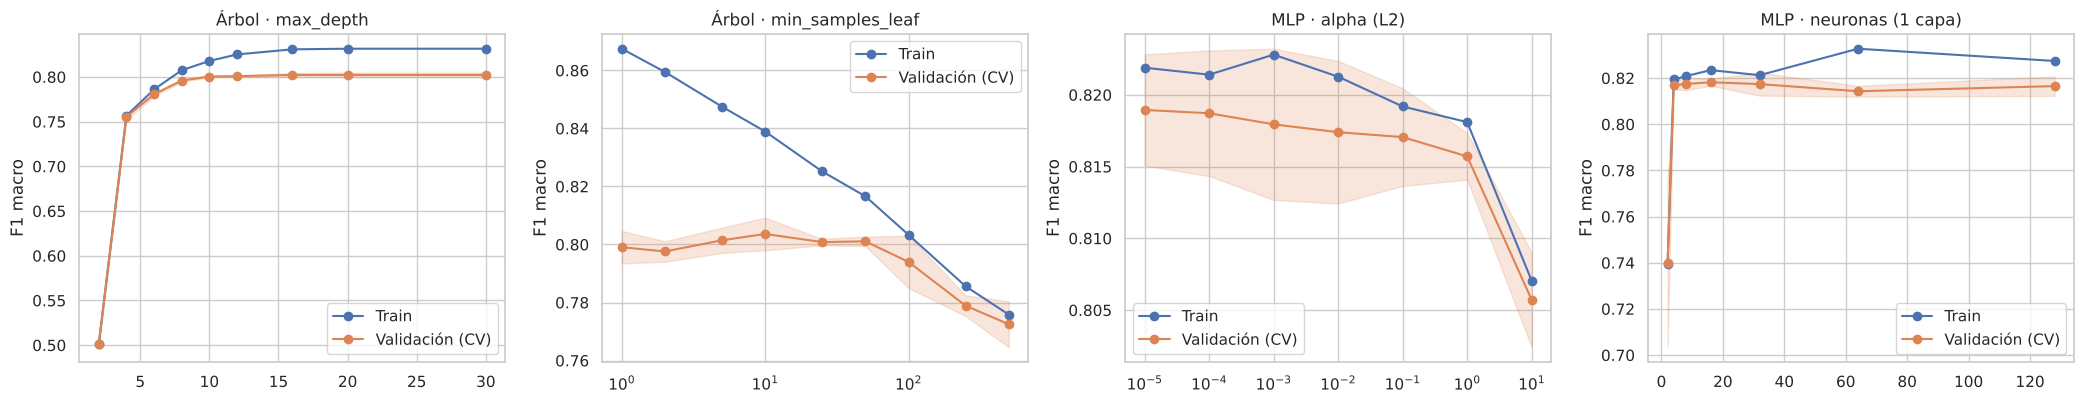

In [ ]:
CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
mlp_base = Pipeline([("scaler", StandardScaler()),
                     ("mlp", MLPClassifier(hidden_layer_sizes=(32,), alpha=1e-2, learning_rate_init=0.01, max_iter=500,
                                           early_stopping=True, n_iter_no_change=10, random_state=RANDOM_STATE))])
curvas = [
    ("Árbol · max_depth", DecisionTreeClassifier(min_samples_leaf=25, random_state=RANDOM_STATE), "max_depth", [2, 4, 6, 8, 10, 12, 16, 20, 30], False),
    ("Árbol · min_samples_leaf", DecisionTreeClassifier(max_depth=12, random_state=RANDOM_STATE), "min_samples_leaf", [1, 2, 5, 10, 25, 50, 100, 250, 500], True),
    ("MLP · alpha (L2)", mlp_base, "mlp__alpha", [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10], True),
    ("MLP · neuronas (1 capa)", mlp_base, "mlp__hidden_layer_sizes", [(2,), (4,), (8,), (16,), (32,), (64,), (128,)], False),
]
fig, axes = plt.subplots(1, 4, figsize=(21, 4.2))
for ax, (titulo, est, param, valores, logx) in zip(axes, curvas):
    tr, va = validation_curve(est, Xtr_demo, ytr_demo, param_name=param, param_range=valores,
                              cv=CV, scoring="f1_macro", n_jobs=-1)
    xs = [v[0] if isinstance(v, tuple) else v for v in valores]
    ax.plot(xs, tr.mean(1), "o-", label="Train"); ax.plot(xs, va.mean(1), "o-", label="Validación (CV)")
    ax.fill_between(xs, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.2, color="C1")
    if logx: ax.set_xscale("log")
    ax.set_title(titulo); ax.set_ylabel("F1 macro"); ax.legend()
plt.tight_layout(); plt.show()

Cada gráfica mueve **un solo hiperparámetro** y compara cómo le va al modelo en train contra validación. Si ambas curvas están bajas, el modelo es demasiado simple y cae en **underfitting**. Esto pasa con un árbol poco profundo (o con `min_samples_leaf` muy grande, por ejemplo). Por el contrario, si la curva de train sigue subiendo mientras la de validación se estanca, el modelo está memorizando y cae en **overfitting**, como pasa con un árbol muy profundo.

Por eso mismo, los rangos del Grid Search (B.5.1 y B.5.2) los elegí **alrededor de la zona óptima** de estas curvas, justo donde la validación llega a su máximo sin que se abra la brecha con train y se caiga al under u overfitting.


## B.6 Modelado: 3 divisiones × 2 modelos + Grid Search
Se realiza un **Grid Search** en cada una de las tres divisiones realizadas (solo con train), para posteriormente elegir una única configuración por modelo, en este caso la de mejor F1 macro promedio en las 3 divisiones.

En cada división se evalúan en test la versión **base** (hiperparámetros por defecto) y la **ajustada** (configuración única).

In [ ]:
PARTICIONES = {"80/20": 0.20, "70/30": 0.30, "60/40": 0.40}

MODELOS = {
    "Árbol de Decisión": {
        "base": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "grid": {"max_depth": [4, 6, 8, 10, 12],
                 "min_samples_leaf": [10, 25, 50, 100],
                 "criterion": ["gini", "entropy"]},
    },
    "Red Neuronal (MLP)": {
        "base": Pipeline([("scaler", StandardScaler()),
                          ("mlp", MLPClassifier(activation="relu", solver="adam", max_iter=500, early_stopping=True,
                                                validation_fraction=0.1, n_iter_no_change=10, random_state=RANDOM_STATE))]),
        "grid": {"mlp__hidden_layer_sizes": [(16,), (32,), (64,), (32, 16), (100,)],
                 "mlp__alpha": [1e-4, 1e-3, 1e-2, 1e-1],
                 "mlp__learning_rate_init": [1e-3, 1e-2]},
    },
}

def metricas(y_true, y_pred, y_prob):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, average="macro"),
            "Recall": recall_score(y_true, y_pred, average="macro"),
            "F1 macro": f1_score(y_true, y_pred, average="macro"),
            "AUC (OvR)": roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro"),
            "Acierto ±1 nivel": np.mean(np.abs(np.asarray(y_true) - y_pred) <= 1)}

In [ ]:
# Paso 1 — Grid Search en cada división (solo con datos de entrenamiento)
datos, grids = {}, {}
for part, test_size in PARTICIONES.items():
    datos[part] = train_test_split(X, y, test_size=test_size, random_state=RANDOM_STATE, stratify=y)
    X_train, X_test, y_train, y_test = datos[part]
    for nombre, cfg in MODELOS.items():
        gs = GridSearchCV(cfg["base"], cfg["grid"], cv=CV, scoring="f1_macro", n_jobs=-1).fit(X_train, y_train)
        grids[(part, nombre)] = pd.DataFrame(gs.cv_results_)

# Paso 2 — Una sola configuración por Modelo: la de mejor F1 macro promedio en las 3 divisiones
config_final, resumen_cfg = {}, []
for nombre in MODELOS:
    tabla_cv = pd.concat({p: grids[(p, nombre)].set_index(grids[(p, nombre)]["params"].astype(str))["mean_test_score"]
                          for p in PARTICIONES}, axis=1)
    tabla_cv["Promedio"] = tabla_cv.mean(axis=1)
    mejor_cfg = tabla_cv["Promedio"].idxmax()
    config_final[nombre] = grids[("80/20", nombre)]["params"][grids[("80/20", nombre)]["params"].astype(str) == mejor_cfg].iloc[0]
    resumen_cfg.append({"Modelo": nombre, "Combinaciones probadas": len(tabla_cv),
                        "Configuración elegida (igual en las 3 divisiones)": {k.replace("mlp__", ""): v for k, v in config_final[nombre].items()},
                        **{f"F1 CV {p}": round(tabla_cv.loc[mejor_cfg, p], 4) for p in PARTICIONES},
                        "F1 CV promedio": round(tabla_cv.loc[mejor_cfg, "Promedio"], 4)})

# Paso 3 — Evaluación de Base vs Ajustado en el test de cada división
resultados, ajustados = [], {}
for part in PARTICIONES:
    X_train, X_test, y_train, y_test = datos[part]
    for nombre, cfg in MODELOS.items():
        for version, modelo in [("Base", clone(cfg["base"])),
                                ("Ajustado", clone(cfg["base"]).set_params(**config_final[nombre]))]:
            modelo.fit(X_train, y_train)
            pred, prob = modelo.predict(X_test), modelo.predict_proba(X_test)
            resultados.append({"Partición": part, "Modelo": nombre, "Versión": version, **metricas(y_test, pred, prob),
                               "F1 train": f1_score(y_train, modelo.predict(X_train), average="macro")})
            if version == "Ajustado":
                ajustados[(part, nombre)] = {"modelo": modelo, "y_test": y_test, "pred": pred, "prob": prob}
                print(f" {part} · {nombre}: F1 macro test = {f1_score(y_test, pred, average='macro'):.4f}")

res = pd.DataFrame(resultados)
pd.DataFrame(resumen_cfg)

 80/20 · Árbol de Decisión: F1 macro test = 0.8051


 80/20 · Red Neuronal (MLP): F1 macro test = 0.8128
 70/30 · Árbol de Decisión: F1 macro test = 0.8038


 70/30 · Red Neuronal (MLP): F1 macro test = 0.8179
 60/40 · Árbol de Decisión: F1 macro test = 0.8034


 60/40 · Red Neuronal (MLP): F1 macro test = 0.8157


,Modelo,Combinaciones probadas,Configuración elegida (igual en las 3 divisiones),F1 CV 80/20,F1 CV 70/30,F1 CV 60/40,F1 CV promedio
0,Árbol de Decisión,40,"{'criterion': 'entropy', 'max_depth': 12, 'min_samples_leaf': 25}",0.8037,0.8032,0.8049,0.8039
1,Red Neuronal (MLP),40,"{'alpha': 0.001, 'hidden_layer_sizes': (64,), 'learning_rate_init': 0.001}",0.8183,0.8179,0.8177,0.8180


### B.6.1 Mapa del Grid Search: F1 macro de validación (promedio de las 3 divisiones)

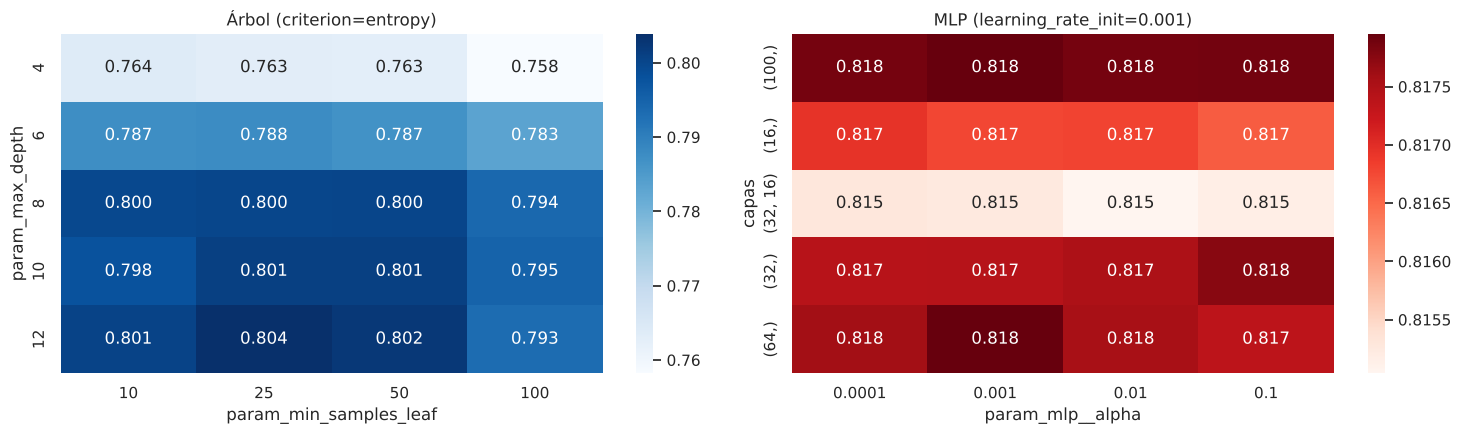

In [ ]:
def grid_promedio(nombre):
    g = pd.concat([grids[(p, nombre)] for p in PARTICIONES])
    g["params_txt"] = g["params"].astype(str)
    return g.groupby([c for c in g.columns if c.startswith("param_")], dropna=False)["mean_test_score"].mean().reset_index()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
g_dt = grid_promedio("Árbol de Decisión")
crit = config_final["Árbol de Decisión"]["criterion"]
piv = g_dt[g_dt["param_criterion"] == crit].pivot_table(index="param_max_depth", columns="param_min_samples_leaf", values="mean_test_score")
sns.heatmap(piv, annot=True, fmt=".3f", cmap="Blues", ax=ax[0]); ax[0].set_title(f"Árbol (criterion={crit})")

g_nn = grid_promedio("Red Neuronal (MLP)")
lr = config_final["Red Neuronal (MLP)"]["mlp__learning_rate_init"]
g_nn["capas"] = g_nn["param_mlp__hidden_layer_sizes"].astype(str)
piv = g_nn[g_nn["param_mlp__learning_rate_init"] == lr].pivot_table(index="capas", columns="param_mlp__alpha", values="mean_test_score")
sns.heatmap(piv, annot=True, fmt=".3f", cmap="Reds", ax=ax[1]); ax[1].set_title(f"MLP (learning_rate_init={lr})")
plt.tight_layout(); plt.show()

## B.7 Evaluación de desempeño

Se utilizaron las métricas de Accuracy, Precision, Recall y F1 (promedio *macro*, que pesa de forma igualitaria las 4 clases), AUC uno-contra-resto y **acierto ±1 nivel**.

Esta última es una métrica de negocio, pues confundir "Alto" con "Crítico" es mucho menos grave que confundir "Bajo" con "Crítico".

### B.7.1 Comparación por división (modelos ajustados)

In [ ]:
METRICAS = ["Accuracy", "Precision", "Recall", "F1 macro", "AUC (OvR)", "Acierto ±1 nivel"]
tabla = res[res["Versión"] == "Ajustado"].set_index(["Partición", "Modelo"])[METRICAS + ["F1 train"]]
tabla.style.highlight_max(subset=METRICAS, color="#2E86AB").format("{:.4f}")

### B.7.2 Gráfica de métricas por modelo y división

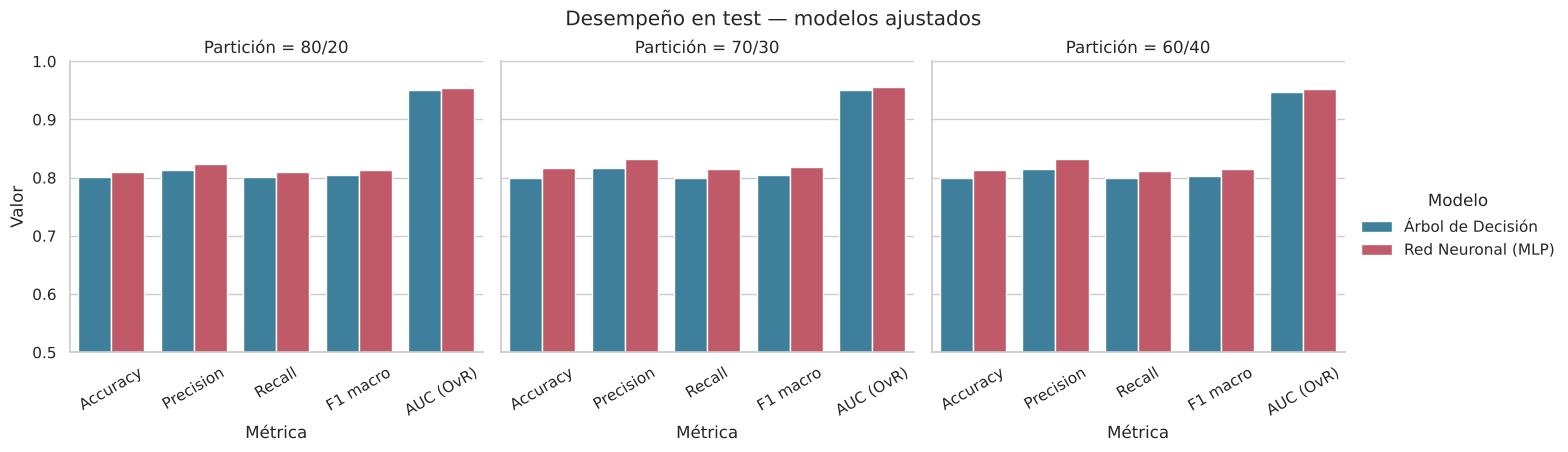

In [ ]:
aj = res[res["Versión"] == "Ajustado"].melt(id_vars=["Partición", "Modelo"], value_vars=METRICAS[:5], var_name="Métrica", value_name="Valor")
g = sns.catplot(data=aj, x="Métrica", y="Valor", hue="Modelo", col="Partición", kind="bar", height=4, aspect=1.15,
                palette=["#2E86AB", "#D1495B"])
for a in g.axes.flat:
    a.set_ylim(0.5, 1.0); a.tick_params(axis="x", rotation=30)
g.fig.suptitle("Desempeño en test — modelos ajustados", y=1.03); plt.show()

### B.7.3 Impacto del ajuste de hiperparámetros: Base vs Ajustado

F1 macro         F1 train          \
Versión                      Ajustado    Base Ajustado    Base   
Partición Modelo                                                 
60/40     Red Neuronal (MLP)   0.8157  0.8150   0.8211  0.8227   
          Árbol de Decisión    0.8034  0.7783   0.8258  1.0000   
70/30     Red Neuronal (MLP)   0.8179  0.8136   0.8230  0.8183   
          Árbol de Decisión    0.8038  0.7987   0.8247  1.0000   
80/20     Red Neuronal (MLP)   0.8128  0.8109   0.8226  0.8214   
          Árbol de Decisión    0.8051  0.7950   0.8266  1.0000   

                             Brecha train–test           
Versión                                   Base Ajustado  
Partición Modelo                                         
60/40     Red Neuronal (MLP)            0.0077   0.0054  
          Árbol de Decisión             0.2217   0.0224  
70/30     Red Neuronal (MLP)            0.0047   0.0051  
          Árbol de Decisión             0.2013   0.0209  
80/20     Red Neuronal (MLP)            0.0105   0.0098  
          Árbol de Decisión             0.2050   0.0215

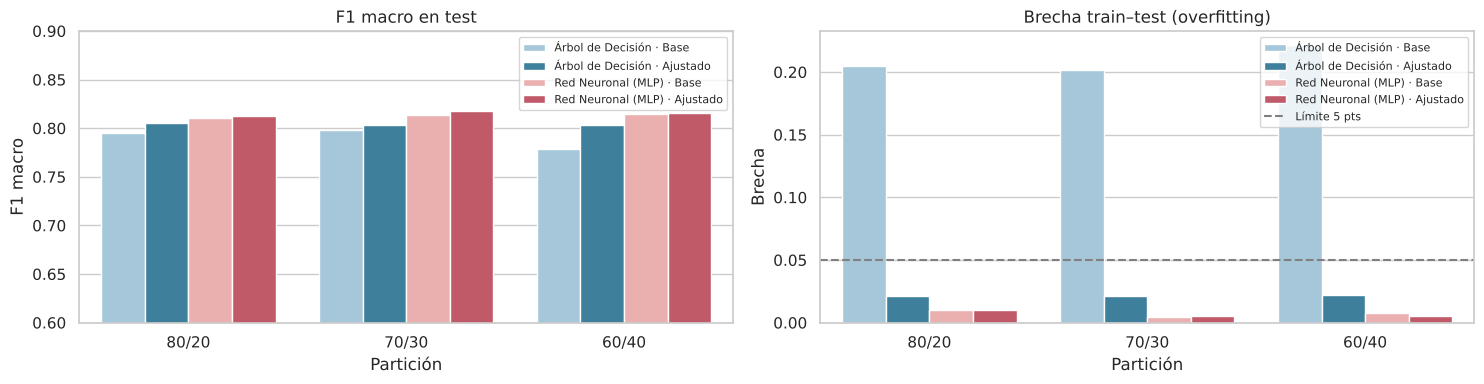

In [ ]:
comp = res.pivot_table(index=["Partición", "Modelo"], columns="Versión", values=["F1 macro", "F1 train"]).round(4)
comp[("Brecha train–test", "Base")] = (comp[("F1 train", "Base")] - comp[("F1 macro", "Base")]).round(4)
comp[("Brecha train–test", "Ajustado")] = (comp[("F1 train", "Ajustado")] - comp[("F1 macro", "Ajustado")]).round(4)
display(comp)

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
etiqueta = res["Modelo"] + " · " + res["Versión"]
pal = ["#9ecae1", "#2E86AB", "#f4a6a6", "#D1495B"]
sns.barplot(data=res, x="Partición", y="F1 macro", hue=etiqueta, palette=pal, ax=ax[0])
ax[0].set_ylim(0.6, 0.9); ax[0].set_title("F1 macro en test"); ax[0].legend(fontsize=8)
sns.barplot(data=res.assign(Brecha=res["F1 train"] - res["F1 macro"]), x="Partición", y="Brecha", hue=etiqueta, palette=pal, ax=ax[1])
ax[1].axhline(0.05, ls="--", c="gray", label="Límite 5 pts"); ax[1].set_title("Brecha train–test (overfitting)"); ax[1].legend(fontsize=8)
print('')
plt.tight_layout(); plt.show()

### B.7.4 Matrices de confusión (normalizadas por la clase real): Árbol vs Red Neuronal

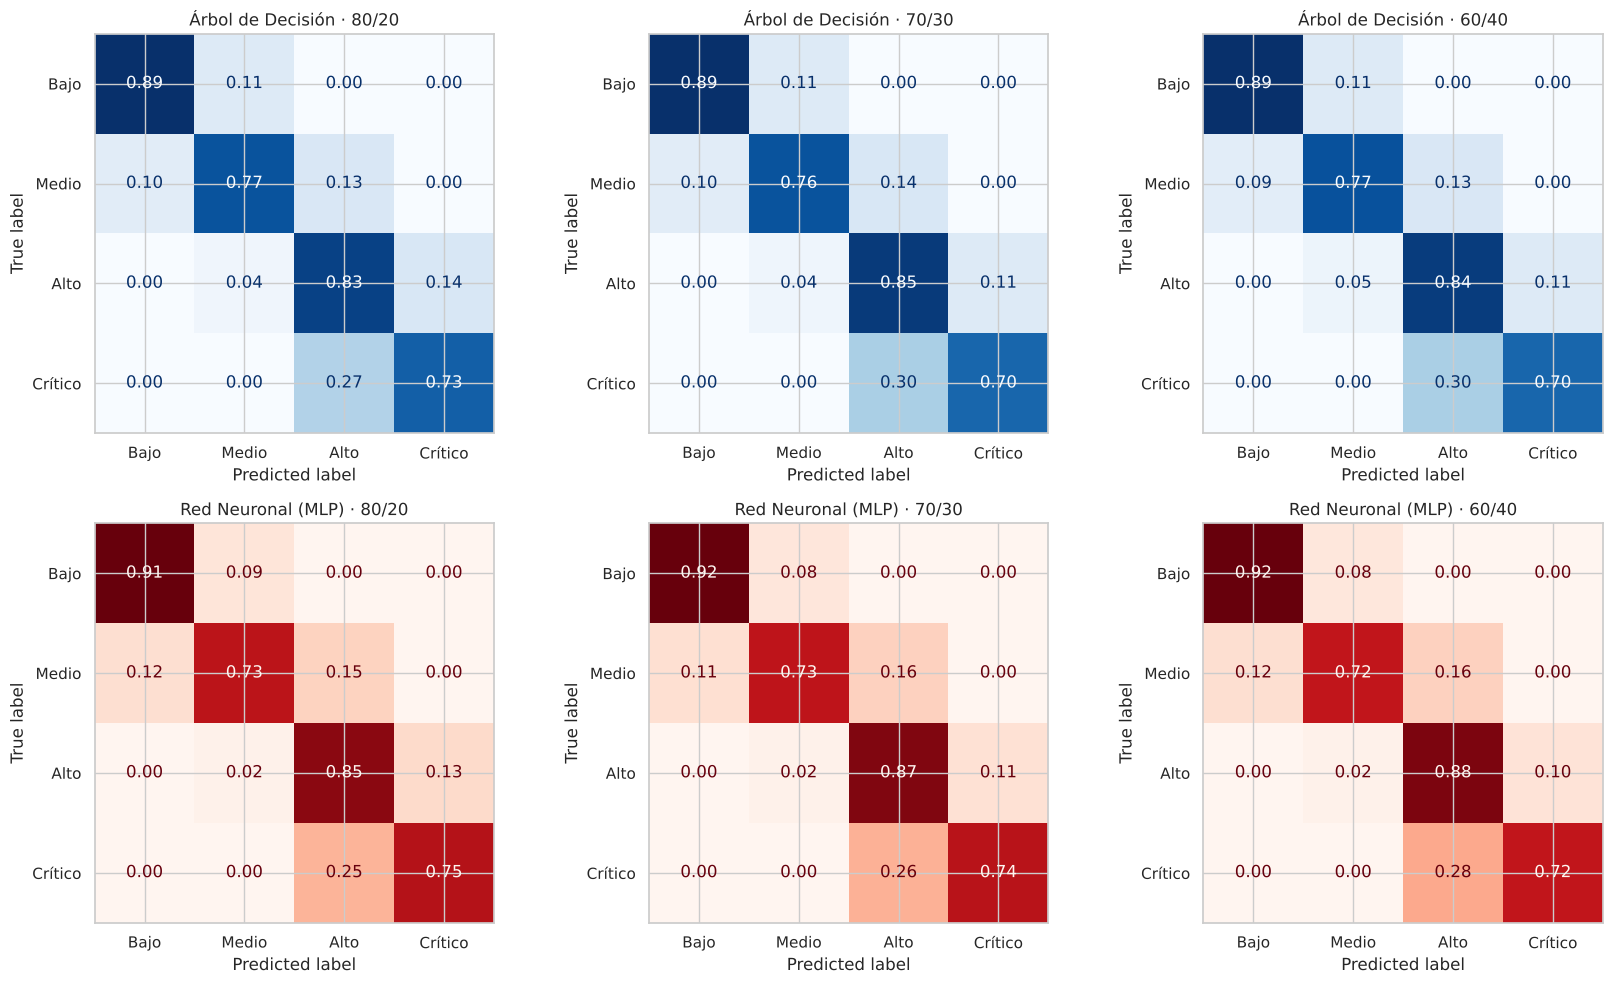

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for j, part in enumerate(PARTICIONES):
    for i, nombre in enumerate(MODELOS):
        r = ajustados[(part, nombre)]
        ConfusionMatrixDisplay(confusion_matrix(r["y_test"], r["pred"], normalize="true"), display_labels=NIVELES).plot(
            ax=axes[i, j], cmap="Blues" if i == 0 else "Reds", colorbar=False, values_format=".2f")
        axes[i, j].set_title(f"{nombre} · {part}")
plt.tight_layout(); plt.show()

### B.7.5 Curvas ROC (uno-contra-resto, partición 80/20)

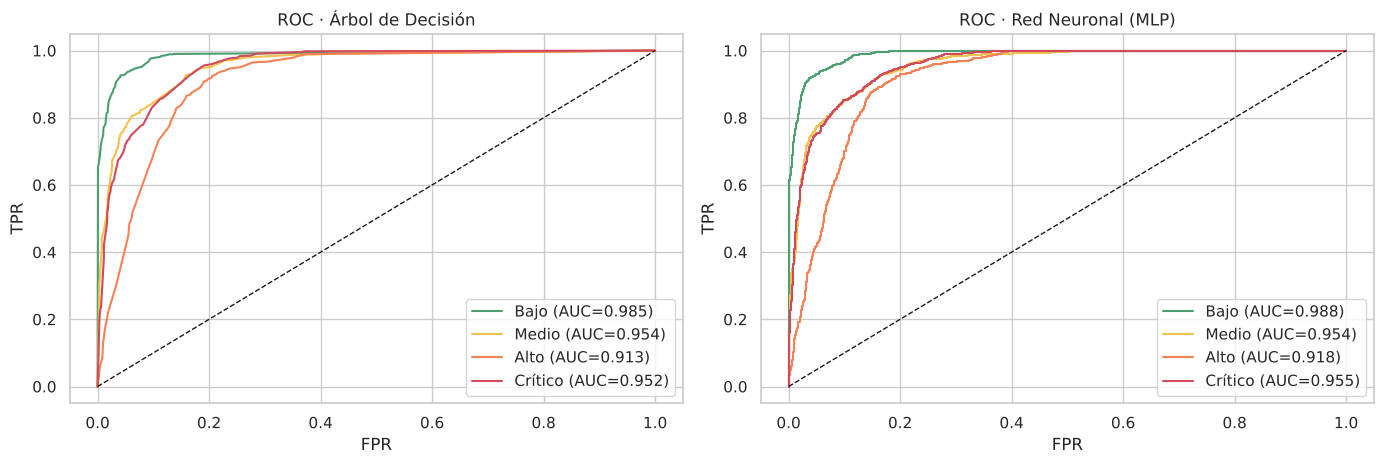

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, nombre in zip(axes, MODELOS):
    r = ajustados[("80/20", nombre)]
    yb = label_binarize(r["y_test"], classes=[0, 1, 2, 3])
    for k in range(4):
        fpr, tpr, _ = roc_curve(yb[:, k], r["prob"][:, k])
        ax.plot(fpr, tpr, color=COLORES[k], label=f"{NIVELES[k]} (AUC={roc_auc_score(yb[:, k], r['prob'][:, k]):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_title(f"ROC · {nombre}"); ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

### B.7.6 Validación temporal: ¿funciona en meses futuros?
Se entrena con los objetivos hasta el mes 18 y se prueba con los últimos meses, que el modelo nunca vio. Es la prueba más realista para un pronóstico.

**Nota:** las divisiones 80/20, 70/30 y 60/40 se hicieron al azar (estratificadas). Como el objetivo es el promedio de 3 meses, dos meses seguidos del mismo producto-región comparten 2 de esos 3 meses, y uno puede quedar en entrenamiento y el otro en prueba. Por eso esta validación temporal, donde los meses de prueba quedan completamente después del entrenamiento, es el resultado más confiable del modelo.

In [ ]:
tr_t, te_t = d["t"] + 3 <= 18, d["t"] >= 18
temporal = {}
for nombre in MODELOS:
    m = clone(ajustados[("80/20", nombre)]["modelo"]).fit(X[tr_t], y[tr_t])
    temporal[nombre] = metricas(y[te_t], m.predict(X[te_t]), m.predict_proba(X[te_t]))
print(f"Train: {tr_t.sum():,} registros (trimestres objetivo dentro de los meses 2–18) | Test: {te_t.sum():,} registros (trimestres objetivo dentro de los meses 19–24)")
pd.DataFrame(temporal).T.round(4)

Train: 13,650 registros (trimestres objetivo dentro de los meses 2–18) | Test: 3,640 registros (trimestres objetivo dentro de los meses 19–24)


,Accuracy,Precision,Recall,F1 macro,AUC (OvR),Acierto ±1 nivel
Árbol de Decisión,0.8102,0.8371,0.8114,0.8118,0.9542,1.0
Red Neuronal (MLP),0.8349,0.8537,0.8343,0.8374,0.9573,1.0


### B.7.7 Pronóstico mes a mes: t+1, t+2 y t+3 por separado
Posteriormente, se reentrenan los modelos ajustados (80/20) para predecir el nivel de **cada mes** del trimestre a predecir. El resultado muestra cómo sería el desempeño con el horizonte establecido, y reafirma por qué conviene pronosticar el trimestre completo.

In [ ]:
horiz = {}
for h in [1, 2, 3]:
    yh = d[f"nivel_t{h}"].astype(int)
    Xh_tr, Xh_te, yh_tr, yh_te = train_test_split(X, yh, test_size=0.2, random_state=RANDOM_STATE, stratify=yh)
    for nombre in MODELOS:
        m = clone(ajustados[("80/20", nombre)]["modelo"]).fit(Xh_tr, yh_tr)
        horiz[(f"t+{h}", nombre)] = metricas(yh_te, m.predict(Xh_te), m.predict_proba(Xh_te))
for nombre in MODELOS:
    horiz[("Trimestre (t+1…t+3)", nombre)] = res.query("Partición=='80/20' and Versión=='Ajustado' and Modelo==@nombre")[METRICAS].iloc[0].to_dict()
pd.DataFrame(horiz).T[["Accuracy", "F1 macro", "AUC (OvR)", "Acierto ±1 nivel"]].round(4)

Accuracy  F1 macro  AUC (OvR)  \
t+1                 Árbol de Decisión     0.6813    0.6829     0.8986   
                    Red Neuronal (MLP)    0.6811    0.6840     0.8973   
t+2                 Árbol de Decisión     0.6894    0.6931     0.9018   
                    Red Neuronal (MLP)    0.6695    0.6707     0.8908   
t+3                 Árbol de Decisión     0.6866    0.6884     0.9014   
                    Red Neuronal (MLP)    0.6695    0.6711     0.8905   
Trimestre (t+1…t+3) Árbol de Decisión     0.8014    0.8051     0.9508   
                    Red Neuronal (MLP)    0.8103    0.8128     0.9541   

                                        Acierto ±1 nivel  
t+1                 Árbol de Decisión             0.9872  
                    Red Neuronal (MLP)            0.9914  
t+2                 Árbol de Decisión             0.9903  
                    Red Neuronal (MLP)            0.9885  
t+3                 Árbol de Decisión             0.9864  
                    Red Neuronal (MLP)            0.9898  
Trimestre (t+1…t+3) Árbol de Decisión             1.0000  
                    Red Neuronal (MLP)            1.0000

### B.7.8 Línea base y robustez: ¿el modelo aporta más que la región?

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
reg_train, reg_test = d.loc[y_train.index, "region"], d.loc[y_test.index, "region"]
moda_region = y_train.groupby(reg_train).agg(lambda s: s.mode()[0])
pred_region = reg_test.map(moda_region).values
lineas = {"Azar (25% por clase)": {"Accuracy": 0.25, "F1 macro": 0.25},
          "Solo región (clase más frecuente por región)": {"Accuracy": accuracy_score(y_test, pred_region),
                                                           "F1 macro": f1_score(y_test, pred_region, average="macro")}}
for nombre in MODELOS:
    r = res.query("Partición=='80/20' and Versión=='Ajustado' and Modelo==@nombre").iloc[0]
    lineas[nombre] = {"Accuracy": r["Accuracy"], "F1 macro": r["F1 macro"]}
pd.DataFrame(lineas).T.round(4)

,Accuracy,F1 macro
Azar (25% por clase),0.2500,0.2500
Solo región (clase más frecuente por región),0.7394,0.7316
Árbol de Decisión,0.8014,0.8051
Red Neuronal (MLP),0.8103,0.8128


## B.8 Predicción: Demanda Esperada × Nivel de Sobrestock Pronosticado

Utilizando la idea del equipo de la matriz, uso el modelo con mejores resultados (Redes Neuronales MLP) para simular cómo podría verse esta matriz, siendo las dimensiones del cubo "Región x Subcategoría x Mes", donde cada celda se ubica en un eje de lo que se conoce hoy, y otra, en el eje que se pronostica.

Para la predicción, se utilizan predicciones del **set de prueba** del mejor modelo, que son registros que el modelo **no vio** al entrenar.

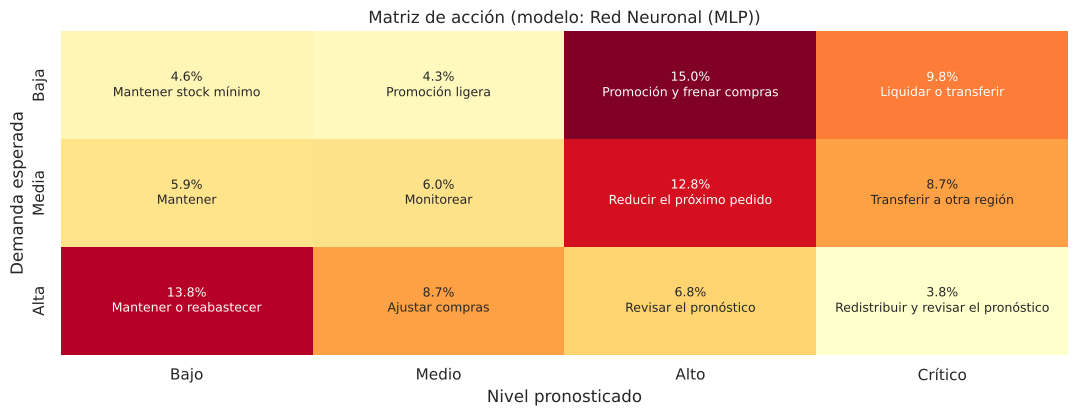

In [ ]:
ajus = res[res["Versión"] == "Ajustado"].sort_values(["F1 macro", "AUC (OvR)"], ascending=False)
mejor = ajus.iloc[0]
r = ajustados[(mejor["Partición"], mejor["Modelo"])]
dt = d.loc[r["y_test"].index].copy()
dt["nivel_pred"] = r["pred"]
dt["demanda_esp"] = pd.qcut(d["units_expected"], 3, labels=["Baja", "Media", "Alta"]).loc[dt.index]
dt["Nivel pronosticado"] = pd.Categorical(dt["nivel_pred"].map(dict(enumerate(NIVELES))), categories=NIVELES)

acciones = pd.DataFrame(
    [["Mantener stock mínimo", "Promoción ligera", "Promoción y frenar compras", "Liquidar o transferir"],
     ["Mantener", "Monitorear", "Reducir el próximo pedido", "Transferir a otra región"],
     ["Mantener o reabastecer", "Ajustar compras", "Revisar el pronóstico", "Redistribuir y revisar el pronóstico"]],
    index=["Baja", "Media", "Alta"], columns=NIVELES)
matriz = pd.crosstab(dt["demanda_esp"], dt["Nivel pronosticado"], normalize=True)
fig, ax = plt.subplots(figsize=(13, 4.2))
sns.heatmap(matriz, annot=matriz.map(lambda v: f"{v:.1%}") + "\n" + acciones.loc[matriz.index, matriz.columns],
            fmt="", cmap="YlOrRd", cbar=False, ax=ax, annot_kws={"fontsize": 9})
ax.set_title(f"Matriz de acción (modelo: {mejor['Modelo']})"); ax.set_ylabel("Demanda esperada"); plt.show()

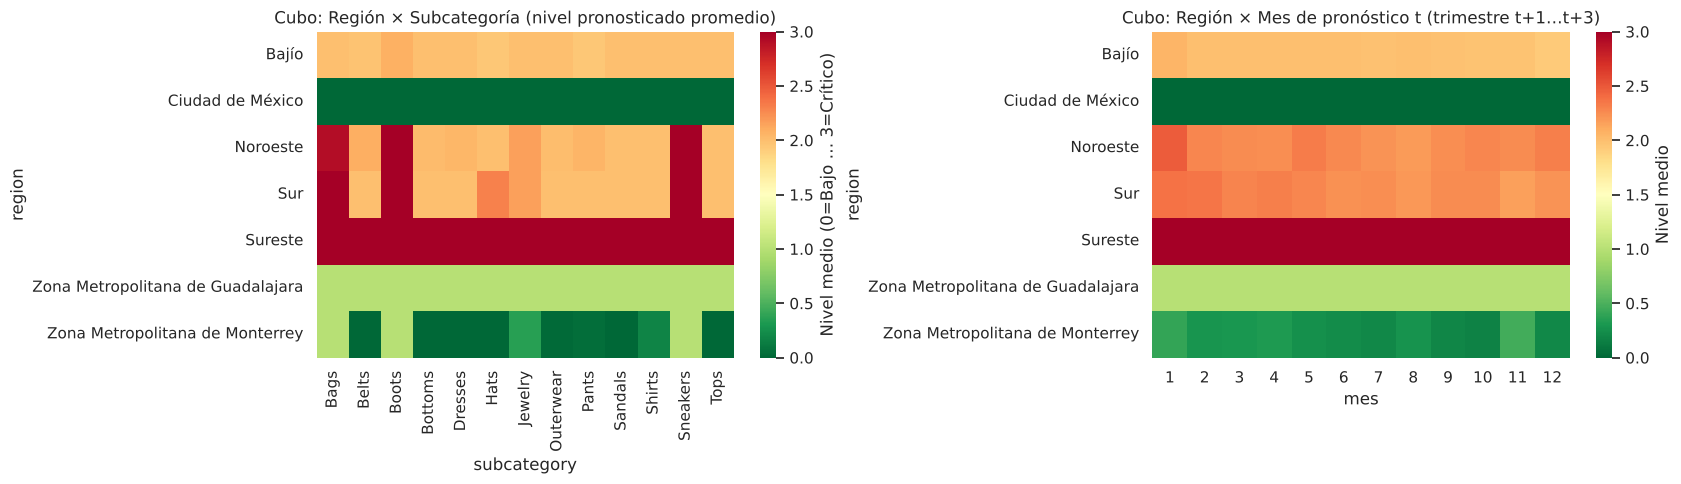

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
cubo_rs = dt.pivot_table(index="region", columns="subcategory", values="nivel_pred", aggfunc="mean")
sns.heatmap(cubo_rs, cmap="RdYlGn_r", vmin=0, vmax=3, ax=ax[0], cbar_kws={"label": "Nivel medio (0=Bajo … 3=Crítico)"})
ax[0].set_title("Cubo: Región × Subcategoría (nivel pronosticado promedio)")
cubo_rm = dt.pivot_table(index="region", columns="mes", values="nivel_pred", aggfunc="mean")
sns.heatmap(cubo_rm, cmap="RdYlGn_r", vmin=0, vmax=3, ax=ax[1], cbar_kws={"label": "Nivel medio"})
ax[1].set_title("Cubo: Región × Mes de pronóstico t (trimestre t+1…t+3)")
plt.tight_layout(); plt.show()

## B.9 Mejor modelo y división

In [ ]:
print(f"Mejor combinación: {mejor['Modelo']} · partición {mejor['Partición']}")
print("Datos del Mejor Modelo: ")
print(f"   Accuracy = {mejor['Accuracy']:.4f} | F1 macro = {mejor['F1 macro']:.4f} | AUC = {mejor['AUC (OvR)']:.4f} | ±1 nivel = {mejor['Acierto ±1 nivel']:.4f}")

print("\nPromedio de las 3 divisiones:")
ajus.groupby("Modelo")[METRICAS + ["F1 train"]].mean().round(4)

Mejor combinación: Red Neuronal (MLP) · partición 70/30
Datos del Mejor Modelo: 
   Accuracy = 0.8158 | F1 macro = 0.8179 | AUC = 0.9554 | ±1 nivel = 1.0000

Promedio de las 3 divisiones:


,Accuracy,Precision,Recall,F1 macro,AUC (OvR),Acierto ±1 nivel,F1 train
Modelo,,,,,,,
Red Neuronal (MLP),0.8133,0.8291,0.8118,0.8155,0.9541,1.0,0.8223
Árbol de Decisión,0.8004,0.8149,0.8006,0.8041,0.9497,1.0,0.8257


## B.10 Demo: ¿Cómo predice el modelo?
Se elige una combinación **región – producto – año – mes (t)**. El modelo pronostica el **nivel de sobrestock del próximo trimestre** (t+1, t+2, t+3) usando **solo la información conocida en el mes t**.


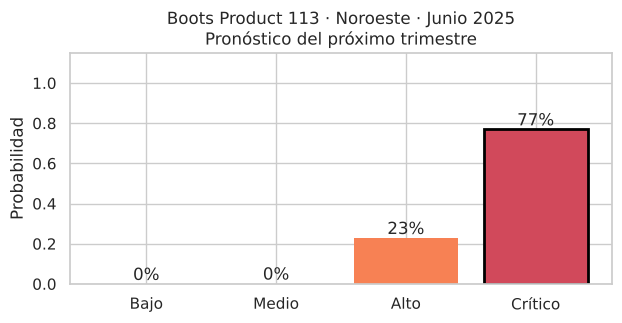

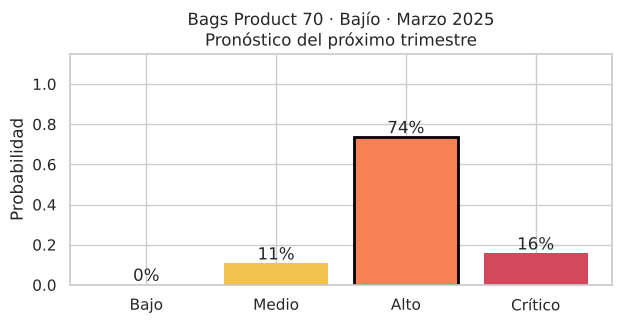

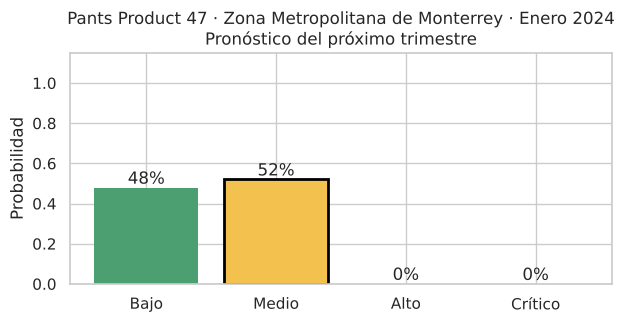

In [ ]:
# Combinación a predecir
REGION, PRODUCTO, ANIO, MES = "Noroeste", 113, 2025, "June"

MESES_ES = dict(zip(mes_map, ["Enero","Febrero","Marzo","Abril","Mayo","Junio","Julio",
                              "Agosto","Septiembre","Octubre","Noviembre","Diciembre"]))
r_best = ajustados[(mejor["Partición"], mejor["Modelo"])]
modelo_demo, idx_test = r_best["modelo"], set(r_best["y_test"].index)
d["demanda_esp"] = pd.qcut(d["units_expected"], 3, labels=["Baja", "Media", "Alta"])

def predecir(region, producto, anio, mes):
    fila = d[(d["region"] == region) & (d["product_id"] == producto) & (d["year"] == anio) & (d["month"] == mes)]
    if fila.empty:
        print("No hay datos para esa combinación (último mes disponible: septiembre 2025)."); return
    f = fila.iloc[0]
    prob = modelo_demo.predict_proba(X.loc[[fila.index[0]]])[0]

    plt.figure(figsize=(7, 3))
    barras = plt.bar(NIVELES, prob, color=COLORES, edgecolor=["black" if p == prob.max() else "none" for p in prob], linewidth=2)
    for b, p in zip(barras, prob): plt.text(b.get_x() + b.get_width() / 2, p + 0.02, f"{p:.0%}", ha="center")
    plt.ylim(0, 1.15); plt.ylabel("Probabilidad")
    plt.title(f"{f['product_name']} · {region} · {MESES_ES[mes]} {anio}\nPronóstico del próximo trimestre")
    plt.show()

predecir(REGION, PRODUCTO, ANIO, MES)
predecir("Bajío", 70, 2025, "March")
predecir("Zona Metropolitana de Monterrey", 47, 2024, "January")

### B.10.1 Ejemplos aleatorios del set de prueba: predicción vs realidad

In [ ]:
muestra = d.loc[sorted(idx_test)].sample(10, random_state=7)
prob_m = modelo_demo.predict_proba(X.loc[muestra.index])
ejemplos = pd.DataFrame({
    "Producto": muestra["product_name"], "Región": muestra["region"],
    "Mes t": muestra["month"].map(MESES_ES) + " " + muestra["year"].astype(str),
    "Pronóstico (t+1…t+3)": [NIVELES[k] for k in prob_m.argmax(1)],
    "Confianza": [f"{p:.0%}" for p in prob_m.max(1)],
    "Real": muestra["nivel_obj"].map(dict(enumerate(NIVELES))),
    "Acción recomendada": [acciones.loc[dem, NIVELES[k]] for dem, k in zip(muestra["demanda_esp"], prob_m.argmax(1))],
})
ejemplos["Acierto"] = np.where(ejemplos["Pronóstico (t+1…t+3)"] == ejemplos["Real"], "True", "False")
ejemplos.reset_index(drop=True)

,Producto,Región,Mes t,Pronóstico (t+1…t+3),Confianza,Real,Acción recomendada,Acierto
0,Pants Product 46,Zona Metropolitana de Guadalajara,Julio 2025,Medio,94%,Medio,Monitorear,True
1,Belts Product 90,Zona Metropolitana de Monterrey,Noviembre 2024,Bajo,83%,Bajo,Mantener stock mínimo,True
2,Shirts Product 41,Noroeste,Diciembre 2024,Alto,75%,Alto,Reducir el próximo pedido,True
3,Dresses Product 57,Sur,Septiembre 2025,Alto,73%,Alto,Reducir el próximo pedido,True
4,Belts Product 94,Zona Metropolitana de Guadalajara,Mayo 2025,Medio,93%,Medio,Monitorear,True
5,Outerwear Product 24,Sureste,Junio 2024,Crítico,86%,Alto,Liquidar o transferir,False
6,Sneakers Product 129,Bajío,Noviembre 2024,Alto,80%,Alto,Revisar el pronóstico,True
7,Boots Product 113,Zona Metropolitana de Guadalajara,Junio 2025,Medio,92%,Medio,Ajustar compras,True
8,Sneakers Product 127,Noroeste,Diciembre 2024,Crítico,67%,Crítico,Redistribuir y revisar el pronóstico,True
9,Shirts Product 43,Sur,Enero 2025,Alto,70%,Alto,Revisar el pronóstico,True


### B.10.2 Tabla de pronóstico por región y mes
Así lo usaría DanuStore: se elige una **región** y un **mes** (y opcionalmente una subcategoría), y el modelo clasifica **cada producto** en su nivel de sobrestock para el próximo trimestre. La tabla se ordena del mayor al menor riesgo.

**Nota:** esta tabla incluye todos los productos de la región y el mes elegidos, tanto los que el modelo usó para entrenar como los de prueba; es una demostración de uso. El desempeño real del modelo se mide en B.7 (prueba) y B.7.6 (meses futuros).

In [ ]:
REGION_T, ANIO_T, MES_T, SUBCAT, MOSTRAR = "Noroeste", 2025, "June", None, 15

def tabla_pronostico(region, anio, mes, subcat=None, mostrar=15):
    f = d[(d["region"] == region) & (d["year"] == anio) & (d["month"] == mes)]
    if subcat: f = f[f["subcategory"] == subcat]
    prob = modelo_demo.predict_proba(X.loc[f.index]); pred = prob.argmax(1)

    t = pd.DataFrame({"Producto": f["product_name"], "Subcategoría": f["subcategory"],
                      "Nivel pronosticado": [NIVELES[k] for k in pred], "Confianza": prob.max(1),
                      "Acción recomendada": [acciones.loc[dm, NIVELES[k]] for dm, k in zip(f["demanda_esp"], pred)],
                      "Nivel real": f["nivel_obj"].map(dict(enumerate(NIVELES))), "orden": pred})
    t["¿Acierto?"] = np.where(t["Nivel pronosticado"] == t["Nivel real"], "True", "False")
    t = t.sort_values(["orden", "Confianza"], ascending=False).drop(columns="orden").reset_index(drop=True)

    print(f"{region} · {MESES_ES[mes]} {anio} → Aciertos: {(t['¿Acierto?'] == 'True').mean():.0%} de {len(t)} productos en total")
    color = dict(zip(NIVELES, COLORES))
    return (t.head(mostrar).style.format({"Confianza": "{:.0%}"})
            .map(lambda v: f"background-color: {color[v]}; color: white; font-weight: bold" if v in color else "",
                 subset=["Nivel pronosticado", "Nivel real"]))

tabla_pronostico(REGION_T, ANIO_T, MES_T, SUBCAT, MOSTRAR)

Noroeste · Junio 2025 → Aciertos: 67% de 130 productos en total


,Producto,Subcategoría,Nivel pronosticado,Confianza,Acción recomendada,Nivel real,¿Acierto?
0,Boots Product 111,Boots,Crítico,82%,Liquidar o transferir,Crítico,True
1,Boots Product 106,Boots,Crítico,81%,Redistribuir y revisar el pronóstico,Crítico,True
2,Boots Product 109,Boots,Crítico,80%,Redistribuir y revisar el pronóstico,Crítico,True
3,Boots Product 105,Boots,Crítico,80%,Liquidar o transferir,Crítico,True
4,Boots Product 108,Boots,Crítico,79%,Redistribuir y revisar el pronóstico,Crítico,True
5,Boots Product 110,Boots,Crítico,79%,Transferir a otra región,Alto,False
6,Boots Product 112,Boots,Crítico,79%,Transferir a otra región,Crítico,True
7,Boots Product 107,Boots,Crítico,78%,Transferir a otra región,Crítico,True
8,Boots Product 114,Boots,Crítico,77%,Redistribuir y revisar el pronóstico,Crítico,True
9,Boots Product 113,Boots,Crítico,77%,Redistribuir y revisar el pronóstico,Crítico,True


Ejemplo con otra región, para comparar (Monterrey, mismo mes):

In [ ]:
tabla_pronostico("Zona Metropolitana de Monterrey", 2025, "June", None, 10)

Zona Metropolitana de Monterrey · Junio 2025 → Aciertos: 78% de 130 productos en total


,Producto,Subcategoría,Nivel pronosticado,Confianza,Acción recomendada,Nivel real,¿Acierto?
0,Sneakers Product 102,Sneakers,Medio,91%,Monitorear,Medio,True
1,Boots Product 108,Boots,Medio,90%,Ajustar compras,Medio,True
2,Boots Product 109,Boots,Medio,89%,Ajustar compras,Medio,True
3,Boots Product 113,Boots,Medio,88%,Ajustar compras,Medio,True
4,Boots Product 112,Boots,Medio,88%,Monitorear,Medio,True
5,Boots Product 106,Boots,Medio,88%,Ajustar compras,Medio,True
6,Boots Product 105,Boots,Medio,88%,Ajustar compras,Medio,True
7,Boots Product 111,Boots,Medio,88%,Monitorear,Medio,True
8,Boots Product 114,Boots,Medio,88%,Ajustar compras,Bajo,False
9,Boots Product 110,Boots,Medio,87%,Ajustar compras,Medio,True


## B.11 Anexo: consistencia del esquema con datos diarios (muestra de 100k transacciones)
La muestra diaria solo cubre **enero 2024**, así que no permite predecir a 3 meses. Se usa para comprobar que **el esquema de 4 niveles y los modelos ajustados** también funcionan a nivel **día × región × producto**, prediciendo el nivel del mismo día.
- Cobertura al día = `Stock_Restante / (Ventas_Acumuladas / día)`, convertida a meses y cortada en cuartiles.
- Se excluyen las mismas variables de salida. Las variables de cliente se descartan porque describen la transacción, no el inventario.
- La base diaria pesa ≈ 750 MB, así que solo se leen las primeras 100,000 filas. Si el archivo no está en la carpeta de datos, la celda avisa y se omite (el resto del notebook no depende de ella).

In [ ]:
if not os.path.exists(RUTA_DIARIO):
    print(f"Anexo omitido: no se encontró {RUTA_DIARIO}")
else:
    data_DanuStore_Diario = pd.read_csv(RUTA_DIARIO, nrows=100_000)
    dd = data_DanuStore_Diario.sort_values("stock_mov_id").head(100_000)
    print("Muestra:", len(dd), "transacciones | Fechas:", dd["date"].min(), "a", dd["date"].max())

    dd = dd[dd["month"] == "January"]
    diario = (dd.groupby(["date", "day", "region", "product_id"])
                .agg(units_expected=("units_expected", "first"), percentage=("percentage", "first"),
                     static_price=("static_price", "first"), subcategory=("subcategory", "first"),
                     acum=("Ventas_Acumuladas", "last"), restante=("Stock_Restante", "last")).reset_index())
    diario["meses_inv"] = diario["restante"] / (diario["acum"] / diario["day"]) / 30.4
    diario["nivel"] = pd.qcut(diario["meses_inv"], 4, labels=False)
    print("Registros:", len(diario), "| Balance:", diario["nivel"].value_counts(normalize=True).sort_index().round(2).tolist())

    Xd = pd.get_dummies(diario[["units_expected", "percentage", "static_price", "day", "region", "subcategory"]],
                        columns=["region", "subcategory"], drop_first=True).astype(float)
    Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, diario["nivel"], test_size=0.2, random_state=RANDOM_STATE, stratify=diario["nivel"])
    anexo = {}
    for nombre in MODELOS:
        m = clone(ajustados[("80/20", nombre)]["modelo"]).fit(Xd_tr, yd_tr)
        anexo[nombre + " · Diario (mismo día)"] = metricas(yd_te, m.predict(Xd_te), m.predict_proba(Xd_te))
    display(pd.DataFrame(anexo).T.round(4))

Anexo omitido: no se encontró ./data_DanuStore_Equipo6.csv


## B.12 Conclusiones de la Parte B

- **Mejor modelo y división:** la **Red Neuronal (MLP) con partición 70/30** (Accuracy 0.816, F1 macro 0.818, AUC 0.955). La MLP superó al Árbol en las 3 divisiones (F1 promedio 0.816 vs 0.804), y entre divisiones la diferencia es de ≈ 0.5 pts, por lo que el resultado es estable.

- **Impacto del preprocesamiento:** la estandarización mejoró la MLP (F1 0.805 → 0.813), quitar `stock` eliminó la multicolinealidad (VIF ≈ 64.5 → ≈ 1) y los cuartiles dejaron las clases balanceadas sin necesidad del remuestreo.

- **Impacto de los hiperparámetros:** con los valores por defecto, el Árbol **memoriza** (F1 train = 1.00, brecha ≈ 21 pts). Ajustado (`max_depth=12`, `min_samples_leaf=25`), la brecha baja a ≈ 2 pts y el F1 de test sube hasta 2.5 pts. La MLP ya partía bien, y el ajuste junto con el *early stopping* mantienen su brecha debajo de 1 pt.

- **¿Es realista?** En meses futuros que el modelo nunca vio, la MLP obtiene F1 0.837. Contra la regla "solo región" (0.73), el modelo agrega ≈ 8 pts. Además, ningún error es de más de un nivel: el modelo solo confunde niveles vecinos.

- **¿Qué hay de la muestra diaria?:** el anexo B.11 necesita la base diaria (≈ 750 MB) en la carpeta de Drive. En la ejecución guardada de este notebook no estaba disponible y el anexo se omitió, por lo que su resultado no se reporta aquí.

- **Limitantes:** (1) las divisiones 80/20, 70/30 y 60/40 son al azar, por lo que pueden ser algo optimistas; el resultado más confiable es el de la validación temporal (F1 0.837). (2) `static_price` es único por producto, así que el modelo podría usarlo para reconocer el producto. (3) Las ventas de 2025 son muy parecidas a las de 2024, lo que facilita el pronóstico. (4) Solo hay ventas de clientes registrados.

Para DanuStore, el hallazgo principal es que **su indicador actual (variable `percentage`) no detecta el sobrestock real**, sino que el pronóstico de demanda está inflado unas 6 veces. El modelo sí lo anticipa con 3 meses de ventaja. Respecto a los hallazgos, por ejemplo, el **Sureste** está en nivel crítico en todo, mientras que **CDMX y Monterrey** rotan rápido y son el destino natural para redistribuir inventario.

NOTA: El modelo identifica bien el nivel estructural de cada producto–región, pero su límite son los cambios de un mes a otro cerca de los cortes entre niveles. Como siguiente paso, propongo agregar el historial reciente de inventario para anticipar esas transiciones.

---
# Conclusiones generales del equipo

Las dos partes se hicieron por separado y con preguntas distintas, pero llegan a la misma lectura del problema de DanuStore:

| | Parte A · Clustering | Parte B · Clasificación |
|---|---|---|
| Pregunta | ¿Qué tipos de producto-región hay? | ¿Qué nivel de sobrestock tendrá el próximo trimestre? |
| Unidad | 910 producto-región (promedio de 24 meses) | 19,110 producto-región-mes |
| Mejor modelo | **K-means C** (`k-means++`, `n_init=50`, k = 3) | **Red Neuronal (MLP)**, partición 70/30 |
| Desempeño | Silueta ≈ 0.352 · Davies-Bouldin ≈ 1.03 (vs 0.328 del jerárquico ward) | F1 macro ≈ 0.818 · AUC ≈ 0.955 · F1 ≈ 0.837 en meses futuros |

- **El sobrestock es general.** En la Parte A ningún cluster llega a una cobertura saludable (menos de 90 días); en la Parte B se vende en promedio solo el 15.7% de lo esperado y apenas el 2.9% de los registros tiene 3 meses de inventario o menos.
- **La región es lo que más pesa.** En la Parte A, CDMX, Monterrey y Guadalajara forman el cluster de mejor rotación (0) y Bajío, Noroeste, Sur y Sureste el de sobrestock severo (2). En la Parte B, la región es la variable con mayor Chi² y la regla "solo región" ya acierta cerca del 74%.
- **El indicador actual no sirve.** La Parte B muestra que `percentage` no detecta el sobrestock real porque el pronóstico de demanda está inflado unas 6 veces; la Parte A muestra que el problema no es cuánto stock hay, sino cuánto hay **comparado con lo que se vende**.
- **Cómo se complementan:** la Parte A dice **qué estrategia** necesita cada producto-región (venta cruzada, descuentos y traspasos para los productos caros, o liquidación) y cuánto dinero está detenido en cada grupo; la Parte B dice **cuándo actuar**, porque anticipa con 3 meses de ventaja el nivel de sobrestock de cada producto-región.
- **Limitantes del equipo:** solo hay 24 meses de datos, las ventas de 2025 son muy parecidas a las de 2024, solo se registran ventas de clientes registrados, y la base no tiene costos, tallas, promociones ni tiempos de reposición. Por eso el dinero detenido de la Parte A se calcula con el precio de venta y es solo una referencia, y los resultados deben validarse con datos nuevos antes de usarse en la operación.


# Referencias

- Breiman, L., Friedman, J., Olshen, R. y Stone, C. (1984). *Classification and regression trees*. Wadsworth.
- Caro, F. y Gallien, J. (2010). Inventory management of a fast-fashion retail network. *Operations Research, 58*(2), 257–273. https://doi.org/10.1287/opre.1090.0698
- Kingma, D. P. y Ba, J. (2015). Adam: A method for stochastic optimization. *International Conference on Learning Representations (ICLR)*. https://arxiv.org/abs/1412.6980
- MacQueen, J. (1967). Some methods for classification and analysis of multivariate observations. *Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability, 1*, 281–297.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7
- Rumelhart, D. E., Hinton, G. E. y Williams, R. J. (1986). Learning representations by back-propagating errors. *Nature, 323*, 533–536. https://doi.org/10.1038/323533a0
- Ward, J. H. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association, 58*(301), 236–244.
